In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *

## Proposition17


In [2]:
from basin import (
    calculate_B_hat,
    calculate_C_hat,
    calculate_D_hat,
    get_aggregate_bounds_prop17,
    theoretical_P_AD_from_ADGT,
    plot_adgt_boa_validation,
    plot_acgt_boundary_validation,
    plot_acad_entry_validation,
    sample_acad_entry_points,
    verify_trajectory_in_basin,
)
from MultiAgent_DQ import Algorithm
from utils import convert_dict_to_mean_df


def theoretical_P_GT_from_ADGT(t, r, p, s, epsilon=None, delta=None, state_idx=0, e=None):
  """B_hat = BoA(pi^GT | (AD,GT))."""
  if epsilon is None:
    epsilon = e
  return calculate_B_hat(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta, state_idx=state_idx)


def theoretical_C_hat_from_ACGT(t, r, p, s, epsilon=None, delta=None, e=None):
  if epsilon is None:
    epsilon = e
  return calculate_C_hat(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta)


def theoretical_D_hat_from_ACAD(t, r, p, s, epsilon=None, delta=None, e=None):
  if epsilon is None:
    epsilon = e
  return calculate_D_hat(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta)



## reading results from simulations


In [3]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_08_05 = pd.read_csv('../results/results_vect_ADGT_0.8_0.5_more_e.csv')
df_07_02 = pd.read_csv('../results/results_vect_ADGT_0.7_0.2_more_e.csv')
df_08_05_uniform = pd.read_csv('../results/results_vect_uniform_0.8_0.5_more_e.csv')
df_07_02_uniform = pd.read_csv('../results/results_vect_uniform_0.7_0.2_more_e.csv')



In [4]:
df_2000_0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/2000_0702.csv')
df_2000_0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/2000_0805.csv')


In [5]:
df_ACGT0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACGT.csv')
df_ACGT0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACGT0702.csv')
df_ADGT0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ADGT.csv')[:225]
df_ADGT0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ADGT.csv')[225:]

import os
_RESULTS = '/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results'
df_ACAD0702 = pd.read_csv(f'{_RESULTS}/results_vect_paramsfixed_time2000_ACAD0702.csv')
df_ACAD0805 = pd.read_csv(f'{_RESULTS}/results_vect_paramsfixed_time2000_ACAD0805.csv')

# ACGT with record_boundary=True (first-crossing columns for C_hat validation)
df_chat_0702 = pd.read_csv(f'{_RESULTS}/ACGT_Chat_validate_0702.csv')
df_chat_0805 = pd.read_csv(f'{_RESULTS}/ACGT_Chat_validate_0805.csv')


In [6]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df




In [7]:
def filter_for_plot(df, na = 5, nl = 8):
    alphas = np.sort(df['alpha'].unique())
    selected = alphas[np.linspace(0, len(alphas) - 1, na).astype(int)]
    lambdas = np.sort(df['lambda'].unique())
    selected_l = lambdas[np.linspace(0, len(lambdas) - 1, nl).astype(int)]
    stric_s = selected_l[:-3]
    df_filtered = df[df['alpha'].isin(selected)]
    df_filtered = df_filtered[df_filtered['lambda'].isin(stric_s)]
    return df_filtered


In [8]:
df_filtered = filter_for_plot(df_07_02, na = 5, nl = 8)
print('alpha values:',df_filtered['alpha'].unique())
print('lambda values:', df_filtered['lambda'].unique())


alpha values: [0.01  0.258 0.505 0.753 1.   ]
lambda values: [0.01  0.092 0.216 0.34  0.422]


In [9]:
df_filtered.M.value_counts()


M
20     375
100    375
500    300
Name: count, dtype: int64

## Uniform Initialization


In [10]:
from basin import *


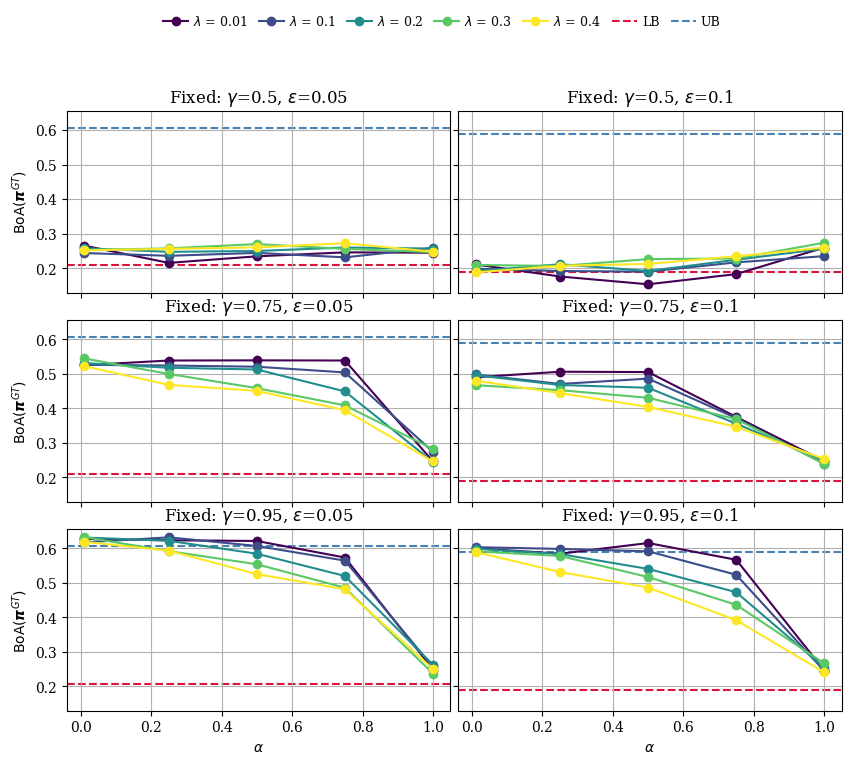

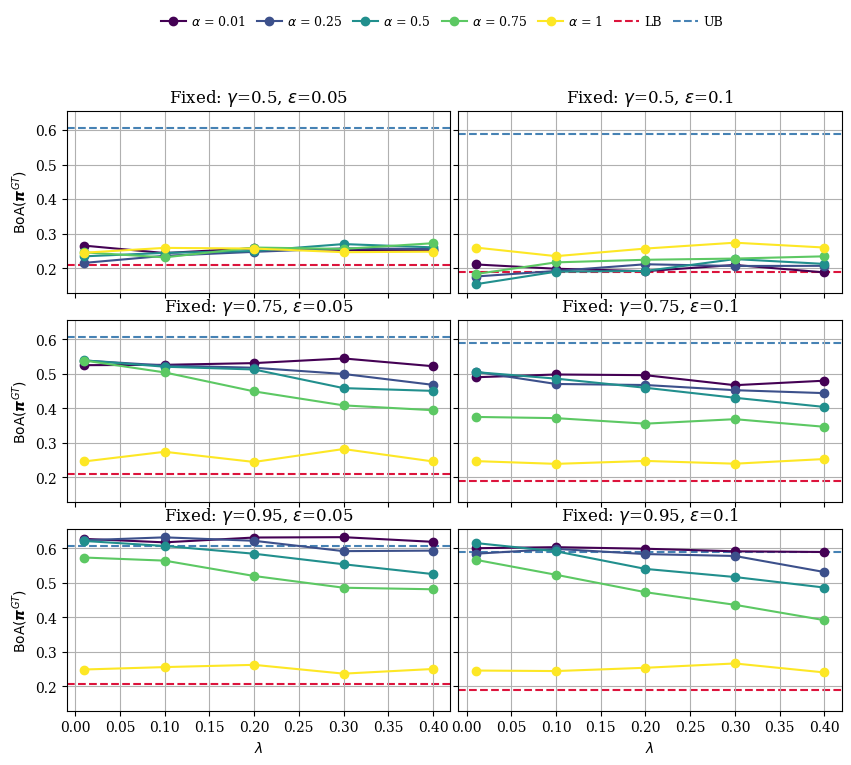

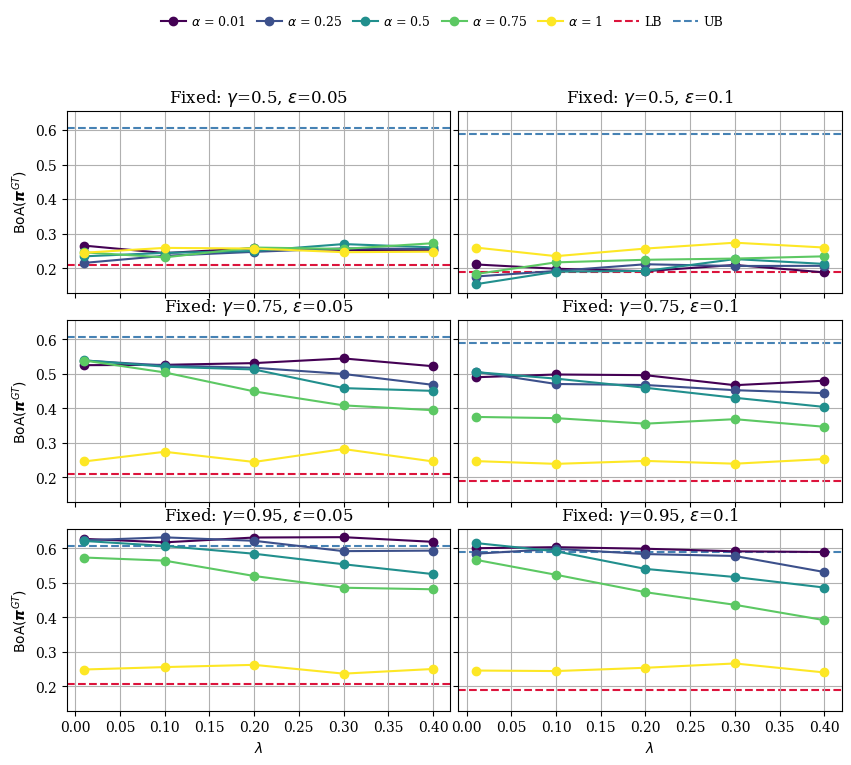

In [11]:
#df_07_02_uniform_filtered = filter_for_plot(df_07_02_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'

t, r, p, s = 1, 0.7, 0.2, 0
theoretical_bounds = [get_aggregate_bounds_prop17(t=t, r=r, p=p, s=s, epsilon=ps['e'], delta=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")
plot_multiple_panels(df_2000_0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")


In [12]:
e, delta = 0.05, 0.95
t, r, p, s = 1, 0.8, 0.5, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)


(0.3402247614650662, 0.6833781705559753)

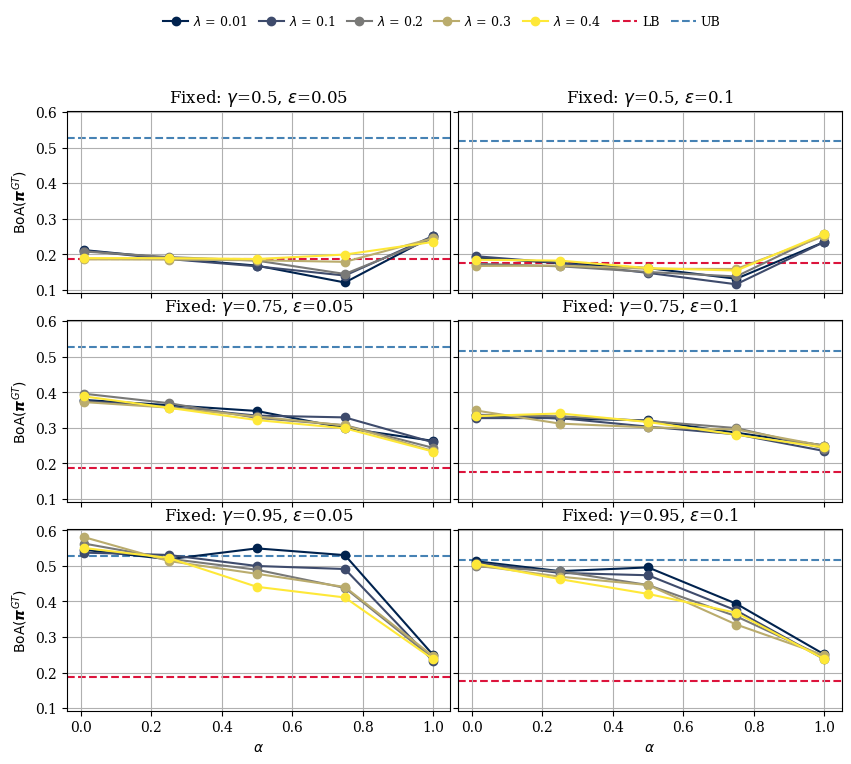

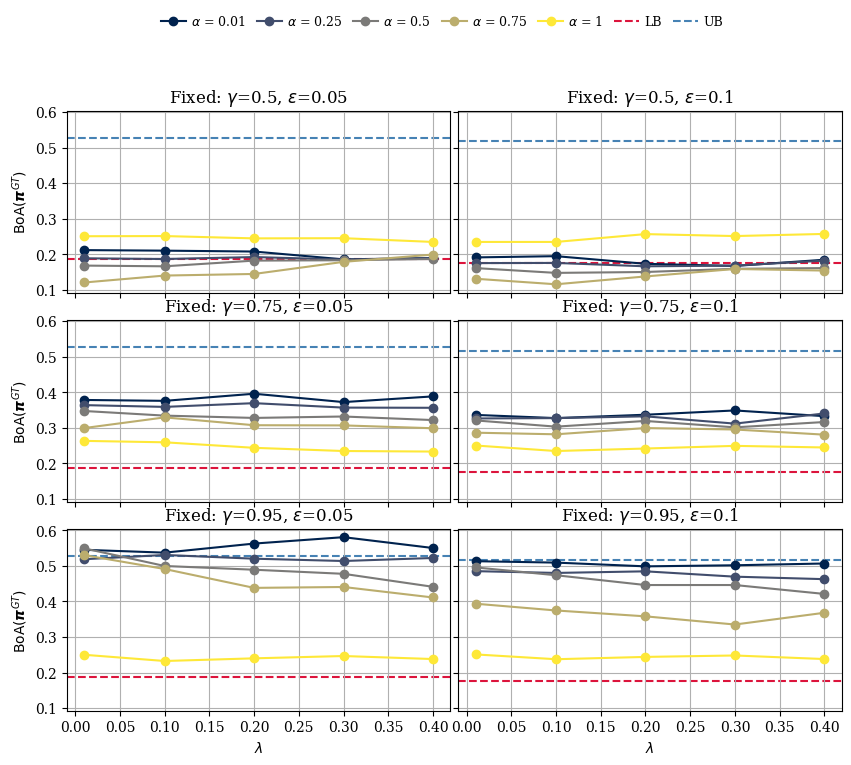

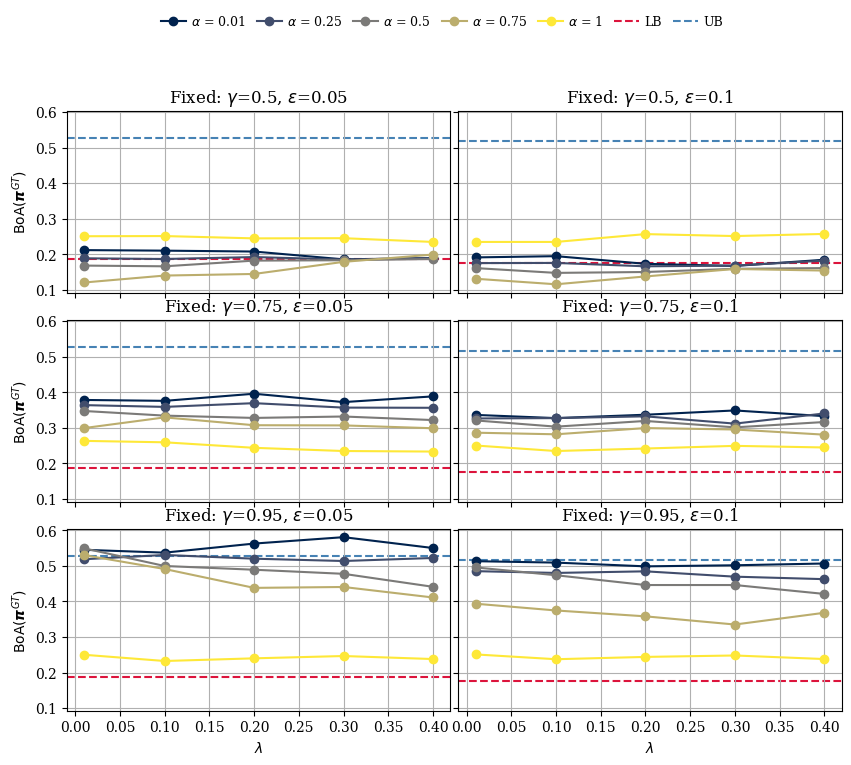

In [13]:
#df_08_05_uniform_filtered = filter_for_plot(df_08_05_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_GT'

t, r, p, s = 1, 0.8, 0.5, 0
theoretical_bounds = [get_aggregate_bounds_prop17(t=t, r=r, p=p, s=s, epsilon=ps['e'], delta=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")
plot_multiple_panels(df_2000_0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")


## ADGT plots


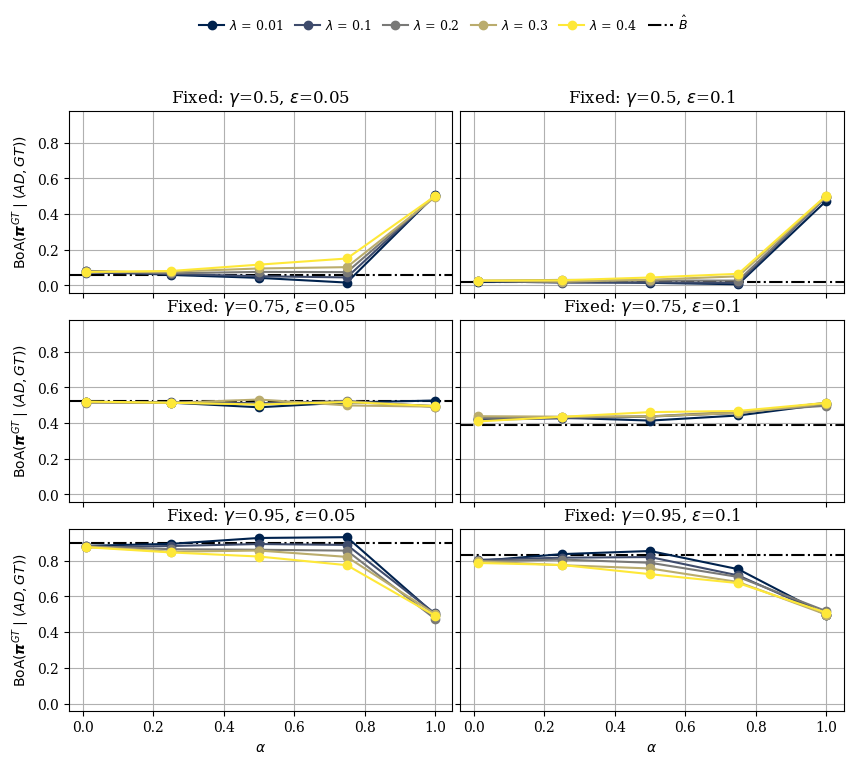

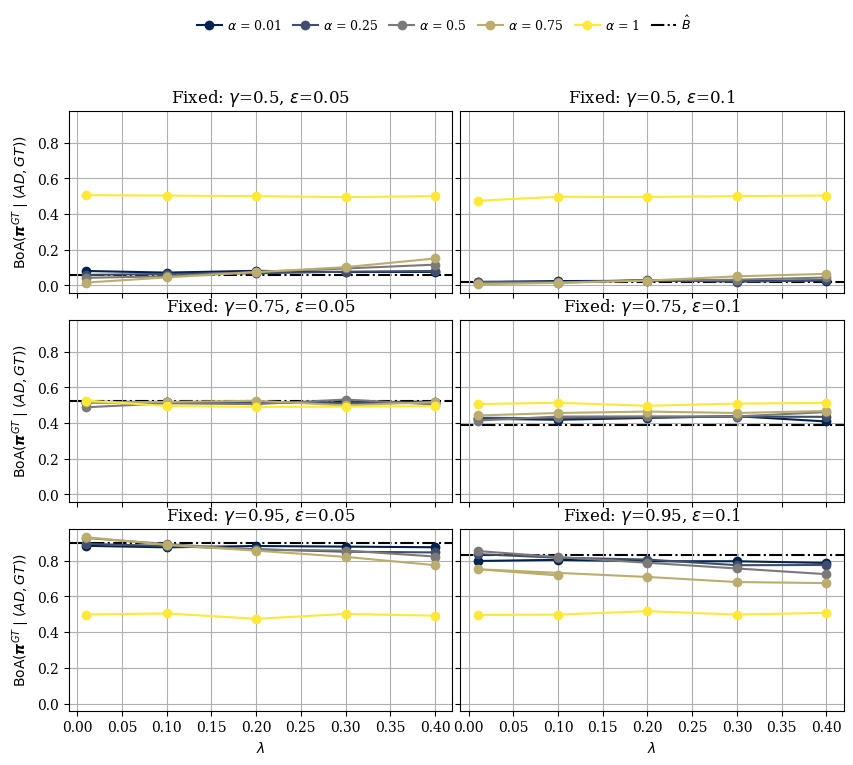

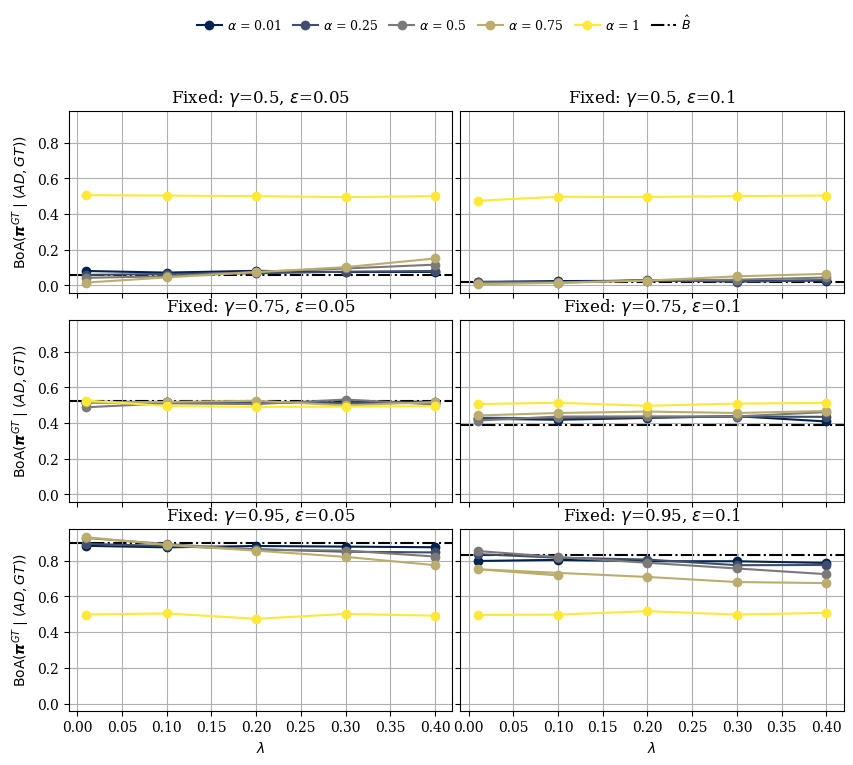

In [14]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_GT'

t, r, p, s = 1, 0.8, 0.5, 0
from MultiAgent.basin import theoretical_P_AD_from_ADGT

theoretical_per_panel = [theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
theoretical_per_panel_c_s = [theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_ADGT0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c_s, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")
plot_multiple_panels(df_ADGT0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c_s, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")


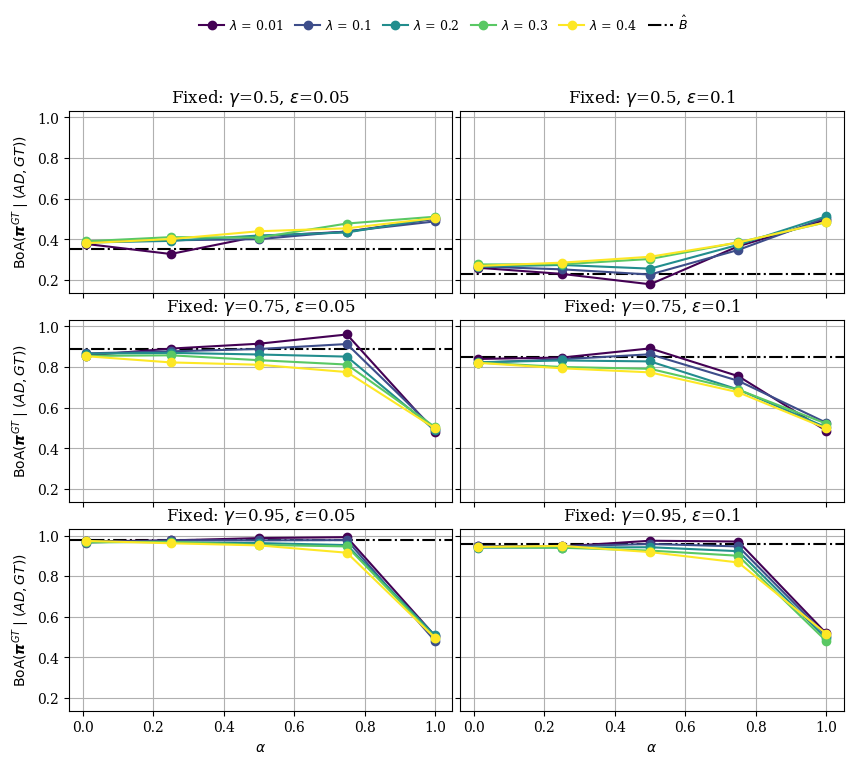

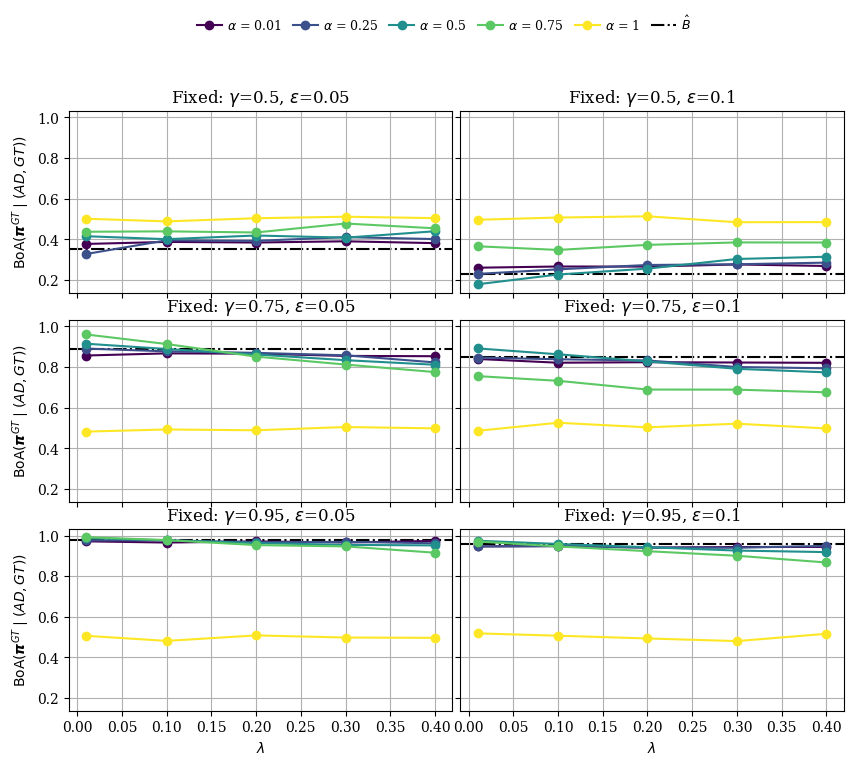

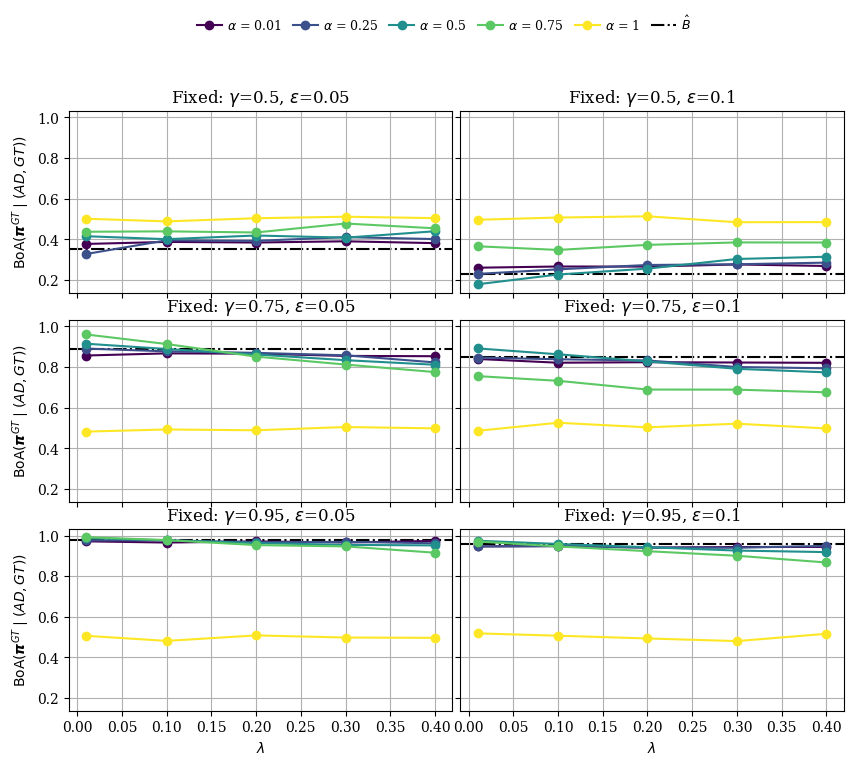

In [15]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

m=2000
y = 'P_GT'
from MultiAgent.basin import theoretical_P_AD_from_ADGT
theoretical_per_panel_c = [theoretical_P_GT_from_ADGT(t=1, r=0.7, p=0.2, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_ADGT0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=m, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")
plot_multiple_panels(df_ADGT0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=m, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")


## ACGT Plots

Plots below use `df_ACGT0702` / `df_ACGT0805` (`results_vect_paramsfixed_time2000_ACGT*.csv`): **`P_GT` only**, vs band $[\hat{C}, 1]$.

For the three-way $\hat{C}$ comparison (`P_direct_GT_analytic`, `P_direct_GT`, `P_GT`), see **Validate $\hat{B}$, $\hat{C}$, $\hat{D}$** — those use `df_chat_*` from `ACGT_Chat_validate_*.csv` (`record_boundary=True`).

| Dataframe | CSV | Crossing columns? |
|-----------|-----|-------------------|
| `df_ACGT_*` | `results_vect_paramsfixed_time2000_ACGT*.csv` | No |
| `df_chat_*` | `ACGT_Chat_validate_*.csv` | Yes: `P_direct_GT`, `P_via_ACAD`, `P_direct_GT_analytic` |


In [16]:
from MultiAgent.basin import theoretical_P_AD_from_ADGT


In [17]:
# Theory helpers are defined in the Proposition17 cell above (imports from basin.py).

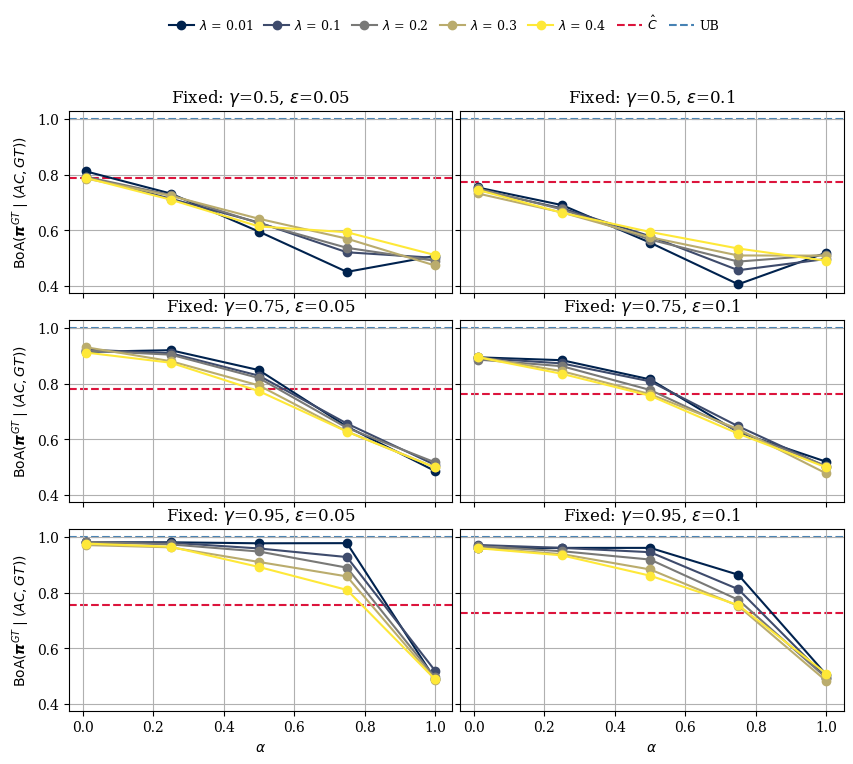

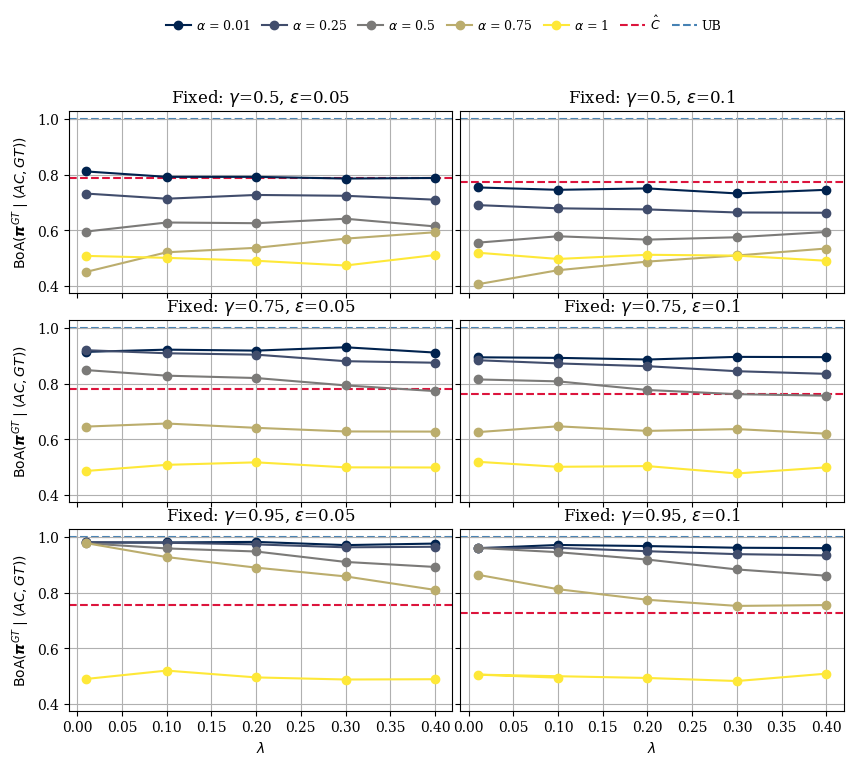

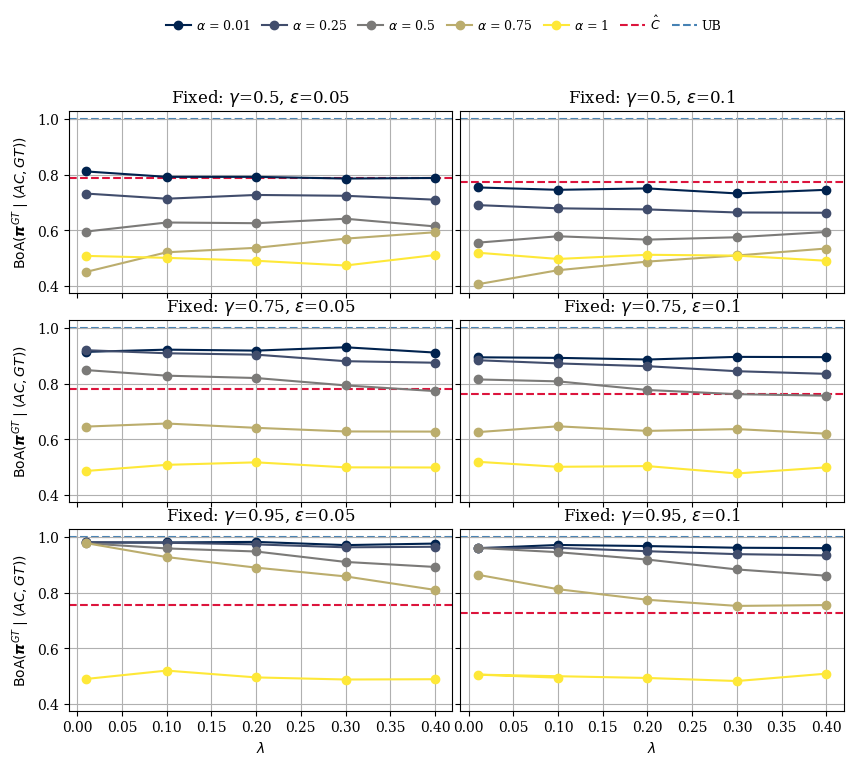

In [18]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'
t, r, p, s = 1, 0.8, 0.5, 0

# Latex reference (ACGT): C-hat <= BoA(pi^GT | (AC,GT)) <= 1
theoretical_bounds_acgt = [
    (theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps['delta'], epsilon=ps['e']), 1.0)
    for ps in param_sets
]

plot_multiple_panels(
    df_ACGT0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y,
    m=2000, use_same_scale=True, cmap='cividis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)
plot_multiple_panels(
    df_ACGT0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y,
    m=2000, use_same_scale=True, cmap='cividis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)


## Boundary validation (Prop. 17)

Analytic basins $\hat B$, $\hat C$, $\hat D$ and aggregate LB/UB with simulation trajectories overlaid. Green/orange/purple shading is the **true** $\alpha\to 0$ boundary; trajectories should stay in the region determined by their initial point.

C-hat band - payoff 0702 (R=0.7, P=0.2)


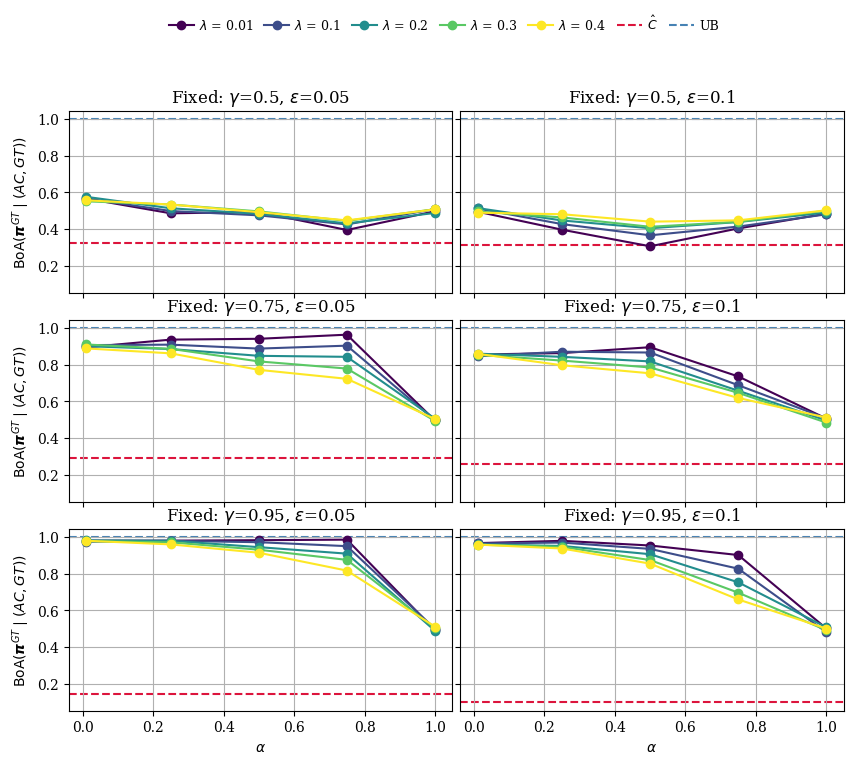

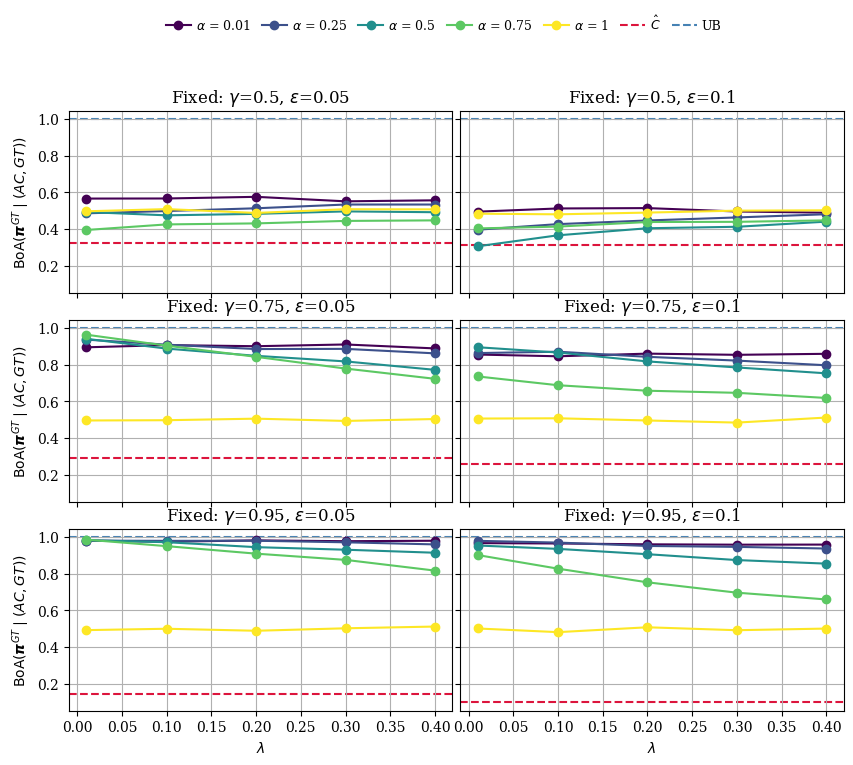

D-hat band - payoff 0702 (R=0.7, P=0.2)


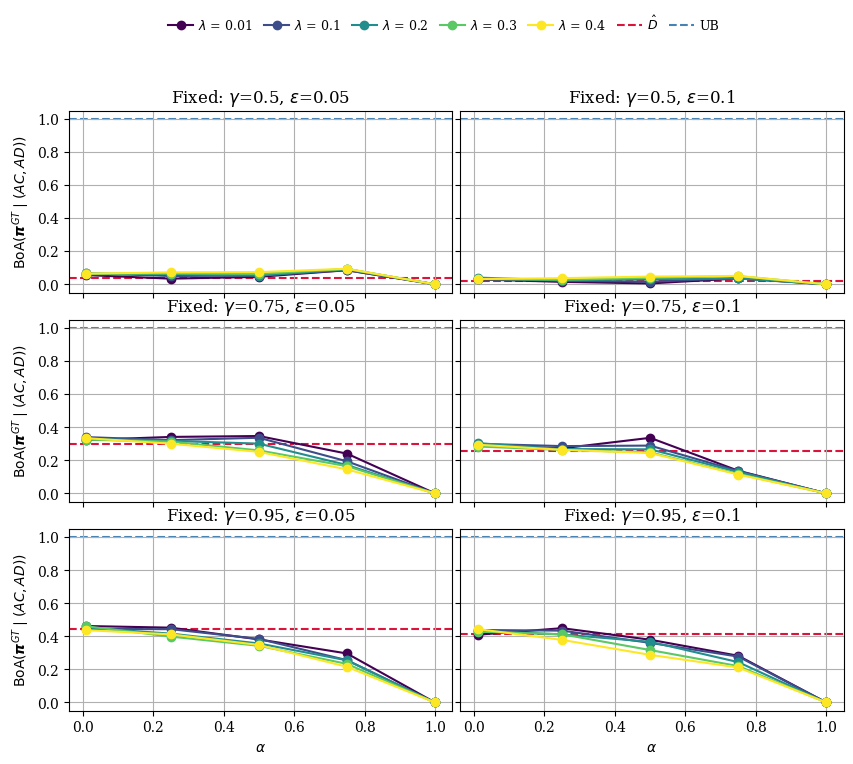

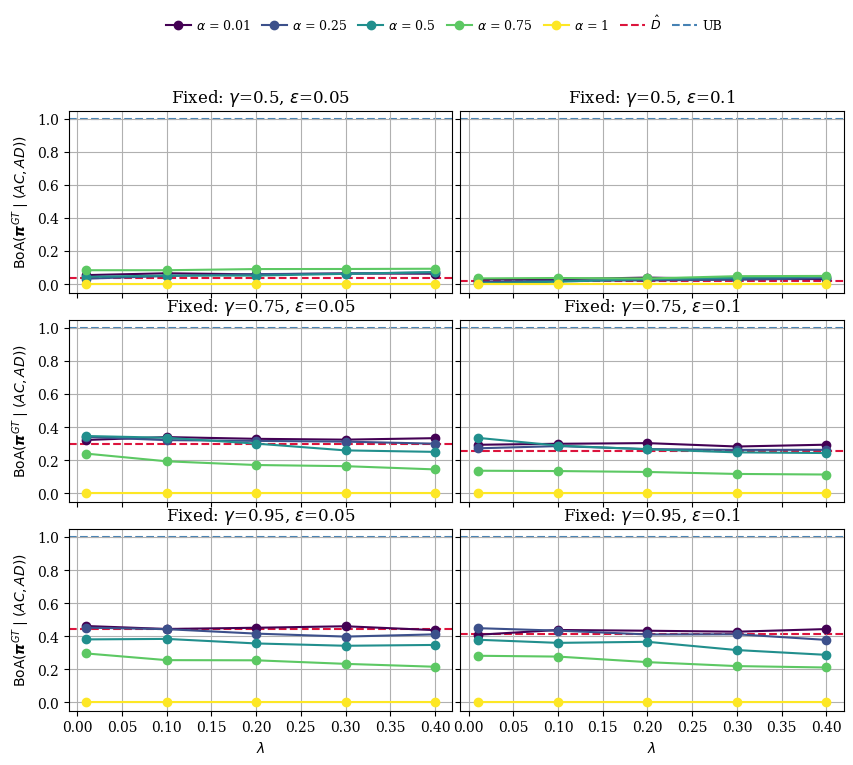

C-hat band - payoff 0805 (R=0.8, P=0.5)


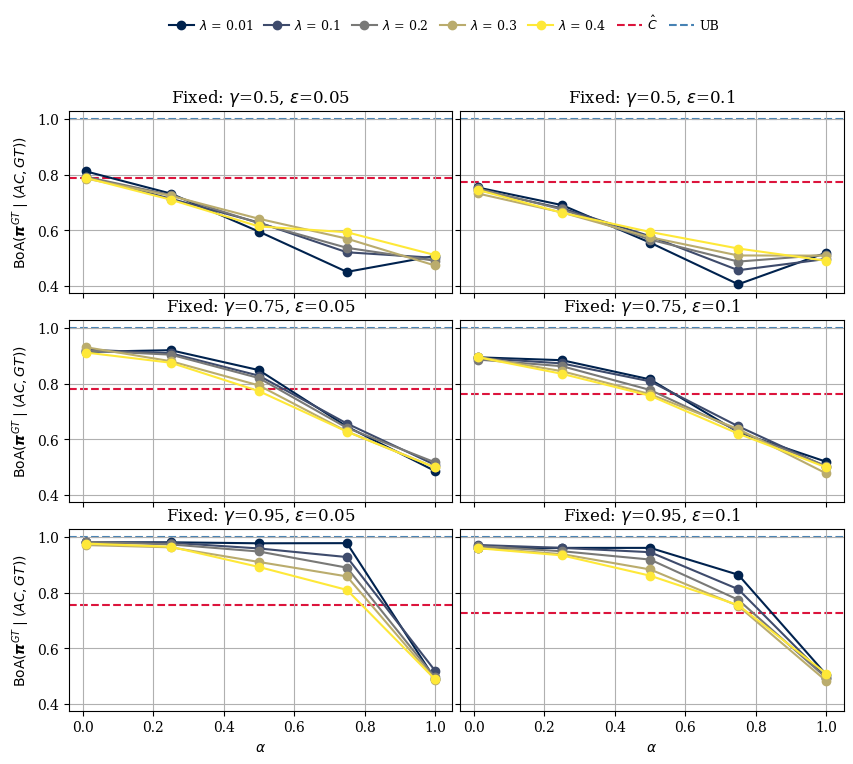

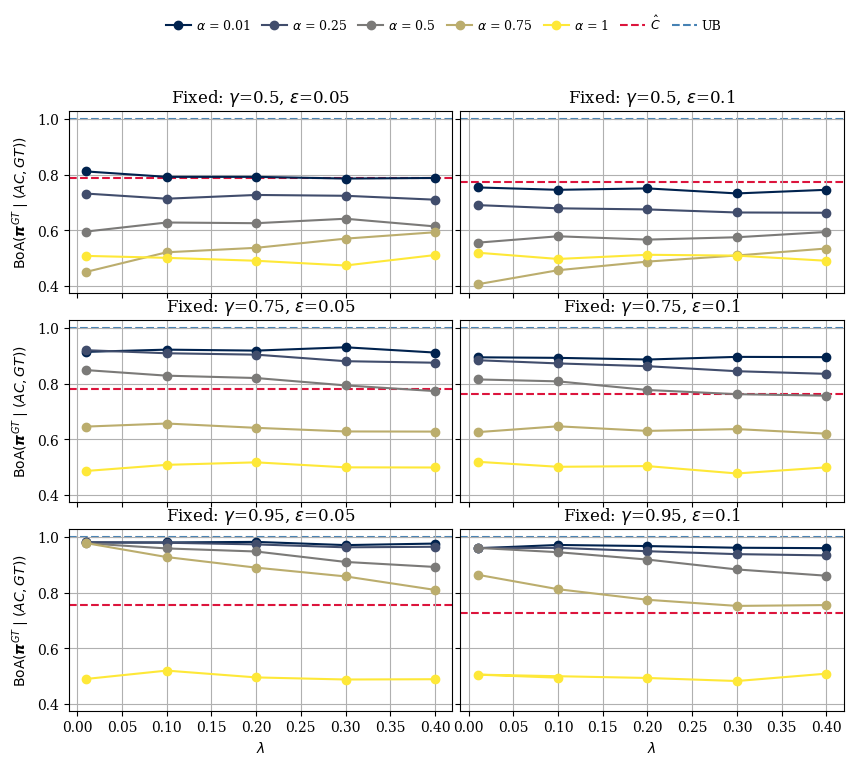

D-hat band - payoff 0805 (R=0.8, P=0.5)


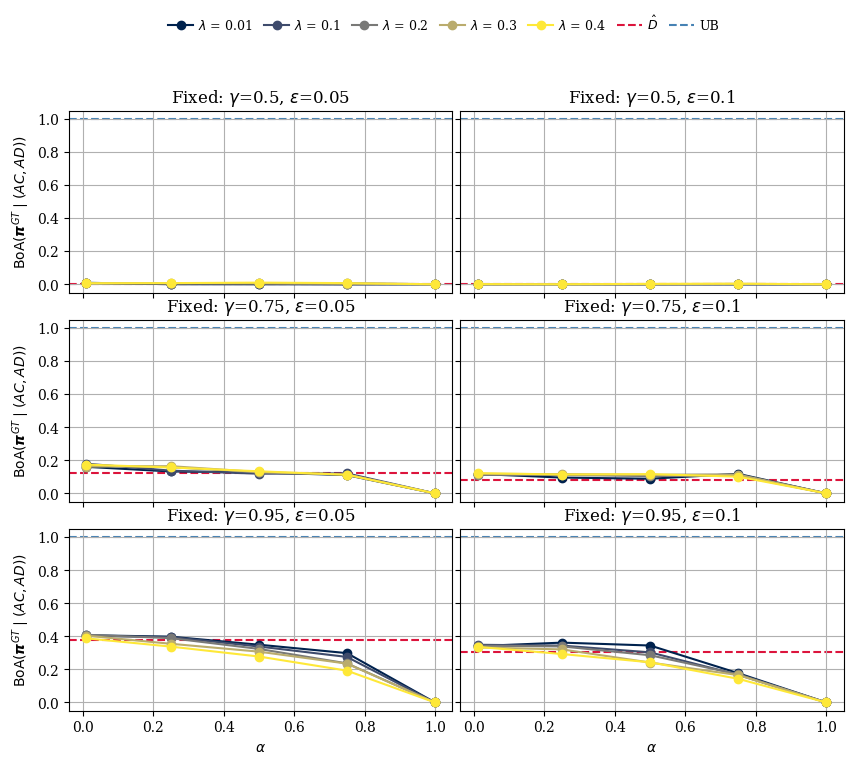

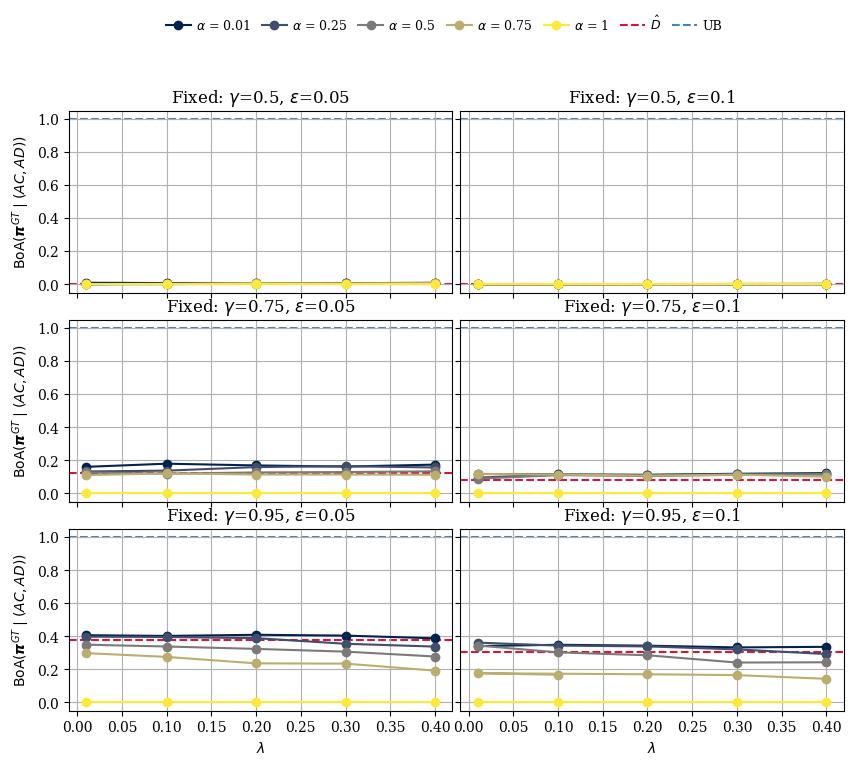

In [19]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'

# (label, ACGT df, ACAD df, payoff (t,r,p,s), colormap)
profile_presets = [
    ('0702', df_ACGT0702, df_ACAD0702, dict(t=1, r=0.7, p=0.2, s=0), 'viridis'),
    ('0805', df_ACGT0805, df_ACAD0805, dict(t=1, r=0.8, p=0.5, s=0), 'cividis'),
]

for label, df_acgt, df_acad, payoff, cmap in profile_presets:
    # C_hat lower bound: BoA(pi^GT | (AC,GT)) in [C_hat, 1]
    bounds_c = [
        (theoretical_C_hat_from_ACGT(delta=ps['delta'], epsilon=ps['e'], **payoff), 1.0)
        for ps in param_sets
    ]
    print(f"C-hat band - payoff {label} (R={payoff['r']}, P={payoff['p']})")
    for x_var, varying_var in [('alpha', 'lambda'), ('lambda', 'alpha')]:
        plot_multiple_panels(
            df_acgt, param_sets, x_var=x_var, varying_var=varying_var, y_var=y,
            m=2000, use_same_scale=True, cmap=cmap, theoretical_bounds=bounds_c,
            theoretical_bounds_labels=(r'$\hat{C}$', 'UB'),
            y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$',
        )

    # D_hat (closed form) lower bound: BoA(pi^GT | (AC,AD)) in [D_hat, 1]
    bounds_d = [
        (theoretical_D_hat_from_ACAD(delta=ps['delta'], e=ps['e'], **payoff), 1.0)
        for ps in param_sets
    ]
    print(f"D-hat band - payoff {label} (R={payoff['r']}, P={payoff['p']})")
    for x_var, varying_var in [('alpha', 'lambda'), ('lambda', 'alpha')]:
        plot_multiple_panels(
            df_acad, param_sets, x_var=x_var, varying_var=varying_var, y_var=y, m=2000,
            use_same_scale=True, cmap=cmap, theoretical_bounds=bounds_d,
            theoretical_bounds_labels=(r'$\hat{D}$', 'UB'),
            y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,AD))$',
        )


R=0.7,P=0.2 — ADGT: stays in initial GT basin = True


<>:47: SyntaxWarning: invalid escape sequence '\p'
<>:47: SyntaxWarning: invalid escape sequence '\p'
/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_48822/1830410141.py:47: SyntaxWarning: invalid escape sequence '\p'
  print(f'{label}uniform aggregate BoA($\pi^{{GT}}$): LB={lb:.3f}, UB={ub:.3f}\n')


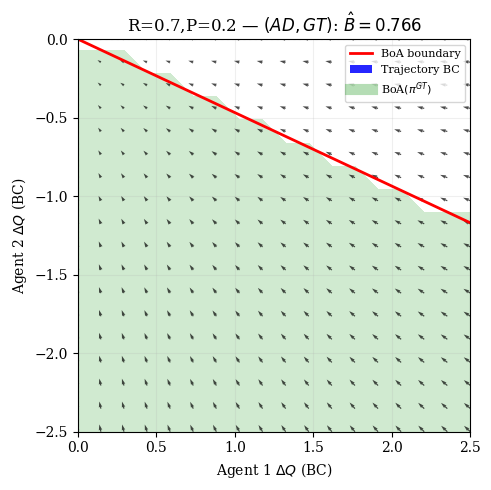

R=0.7,P=0.2 — ACGT: start in Ĉ region = 0


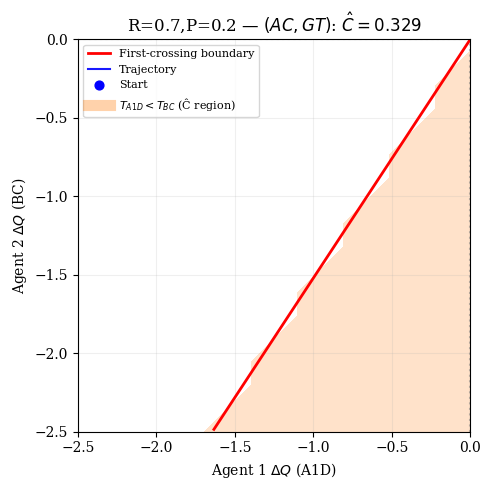

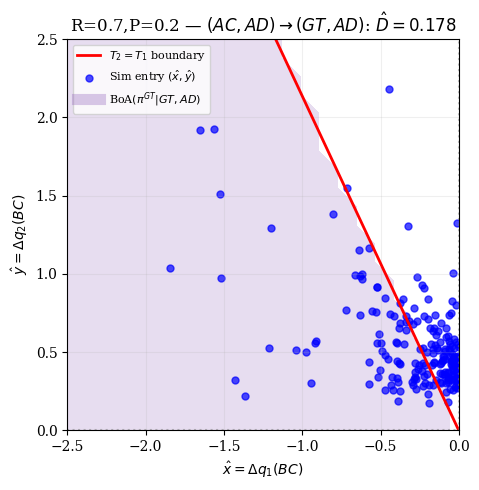

R=0.7,P=0.2 — uniform aggregate BoA($\pi^{GT}$): LB=0.222, UB=0.618

R=0.8,P=0.5 — ADGT: stays in initial GT basin = True


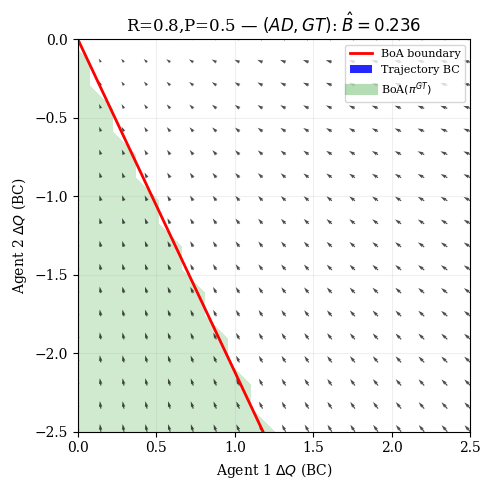

R=0.8,P=0.5 — ACGT: start in Ĉ region = 0


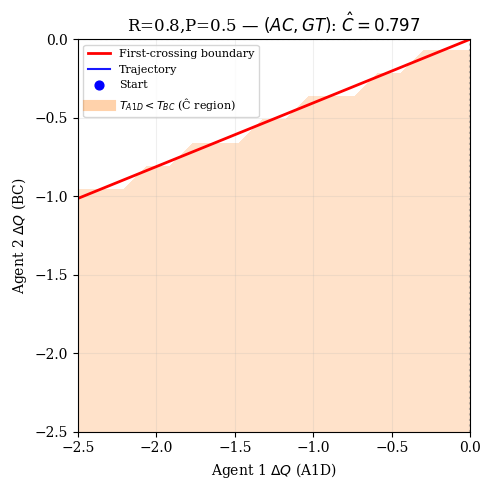

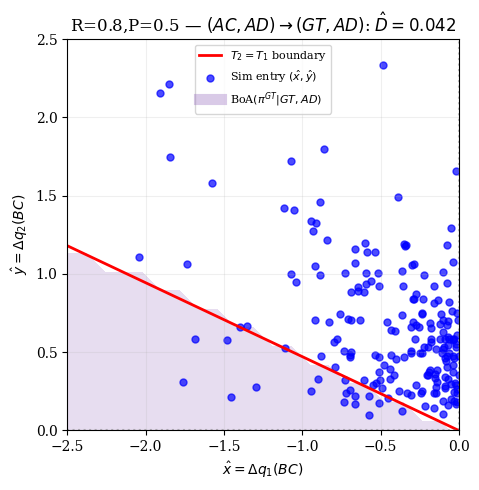

R=0.8,P=0.5 — uniform aggregate BoA($\pi^{GT}$): LB=0.197, UB=0.535



In [20]:
# Prop. 17 boundary validation: analytic shaded basins + simulation trajectories

def _run_one_trajectory(strategy1, strategy2, t, r, p, s, e, delta, alpha, lam, seed=0):
    np.random.seed(seed)
    algo = Algorithm(
        e=e, lambda_val=lam, alpha=alpha, delta=delta,
        init_mode='uniform', tolerance=1e-10, M=1,
        strategy1=strategy1, strategy2=strategy2,
        t=t, r=r, p=p, s=s, verbose=False,
    )
    q1h, q2h, _, _, _ = algo.run()
    return convert_dict_to_mean_df(q1h, mean=False)[0], convert_dict_to_mean_df(q2h, mean=False)[0]


def plot_prop17_boundaries_for_config(t, r, p, s, e, delta, alpha=0.01, lam=0.01, seed=7, label=''):
  b_hat = calculate_B_hat(t, r, p, s, e, delta)
  c_hat = calculate_C_hat(t, r, p, s, e, delta)
  d_hat = calculate_D_hat(t, r, p, s, e, delta, n_mc=150000)

  q1, q2 = _run_one_trajectory('AD', 'GT', t, r, p, s, e, delta, alpha, lam, seed=seed)
  fig, ax = plt.subplots(figsize=(6, 5))
  plot_adgt_boa_validation(
      t=t, r=r, p=p, s=s, epsilon=e, d=delta, q1=q1, q2=q2, alpha=alpha, ax=ax,
      title=rf'{label}$(AD,GT)$: $\hat{{B}}={b_hat:.3f}$',
  )
  chk = verify_trajectory_in_basin(q1, q2, 'ADGT', t, r, p, s, e, delta)
  print(f'{label}ADGT: stays in initial {chk["initial_basin"]} basin = {chk["stays_in_initial_basin"]}')
  plt.tight_layout(); plt.show()

  q1, q2 = _run_one_trajectory('AC', 'GT', t, r, p, s, e, delta, alpha, lam, seed=seed + 1)
  fig, ax = plot_acgt_boundary_validation(
      t=t, r=r, p=p, s=s, epsilon=e, d=delta, q1=q1, q2=q2, alpha=alpha,
      title=rf'{label}$(AC,GT)$: $\hat{{C}}={c_hat:.3f}$',
  )
  chk = verify_trajectory_in_basin(q1, q2, 'ACGT', t, r, p, s, e, delta)
  print(f'{label}ACGT: start in Ĉ region = {chk["initial_in_C_region"]:.0f}')
  plt.tight_layout(); plt.show()

  xh, yh = sample_acad_entry_points(t, r, p, s, e, delta, n=200, seed=seed + 2)
  fig, ax = plot_acad_entry_validation(
      t=t, r=r, p=p, s=s, epsilon=e, d=delta, entry_points=(xh, yh),
      title=rf'{label}$(AC,AD)\to(GT,AD)$: $\hat{{D}}={d_hat:.3f}$',
  )
  plt.tight_layout(); plt.show()

  lb, ub = get_aggregate_bounds_prop17(t, r, p, s, e, delta)
  print(f'{label}uniform aggregate BoA($\pi^{{GT}}$): LB={lb:.3f}, UB={ub:.3f}\n')


for cfg, name in [((1, 0.7, 0.2, 0), 'R=0.7,P=0.2 — '), ((1, 0.8, 0.5, 0), 'R=0.8,P=0.5 — ')]:
    t, r, p, s = cfg
    plot_prop17_boundaries_for_config(t, r, p, s, e=0.01, delta=0.6, alpha=0.01, lam=0.01, label=name)

Aggregate Prop. 17 bounds - payoff 0702 (R=0.7, P=0.2)


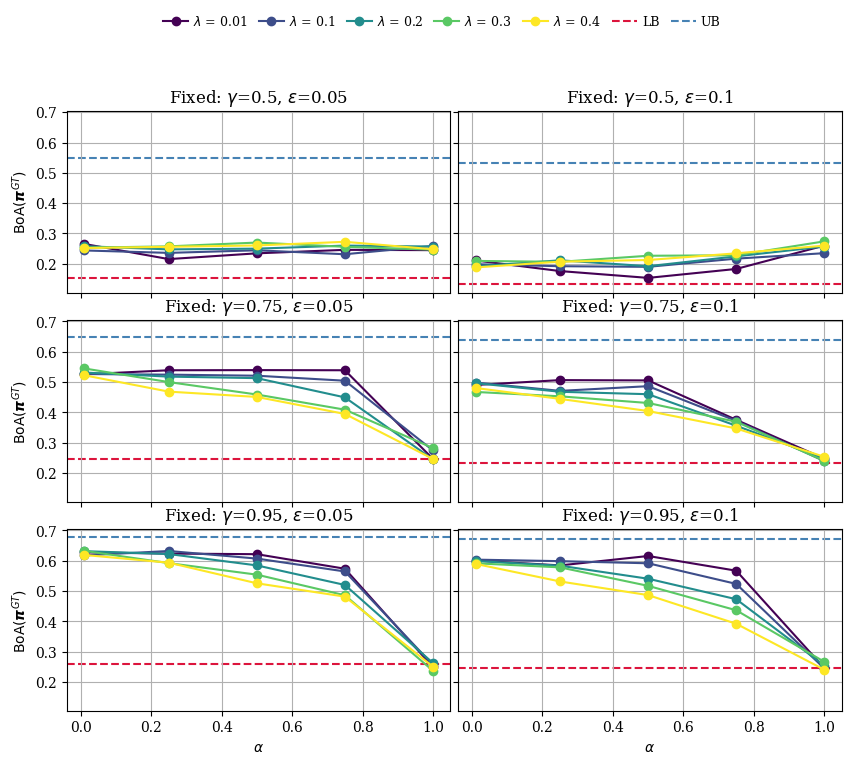

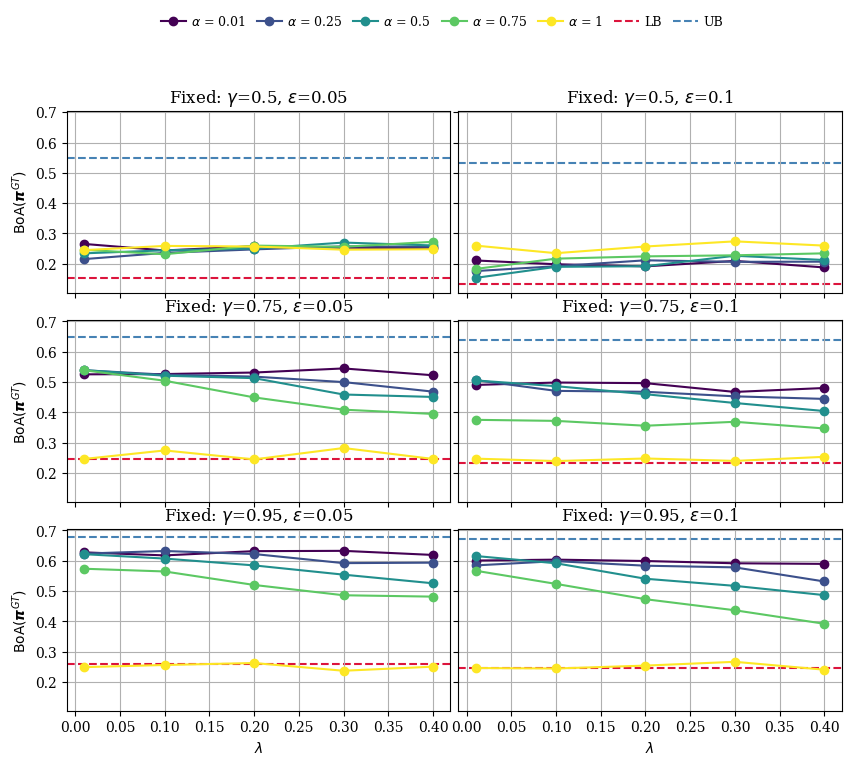

Aggregate Prop. 17 bounds - payoff 0805 (R=0.8, P=0.5)


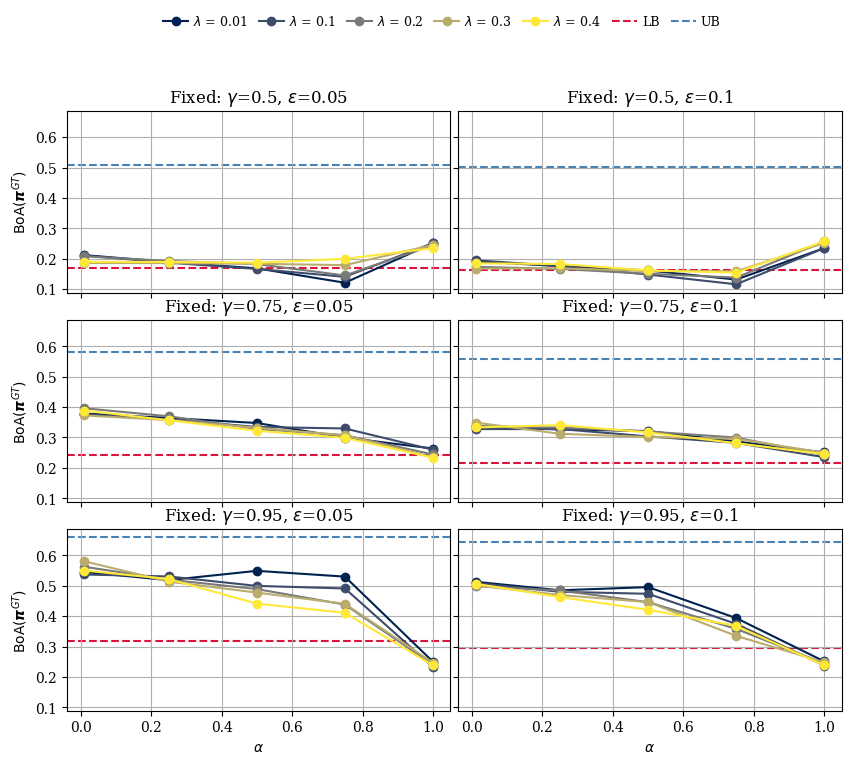

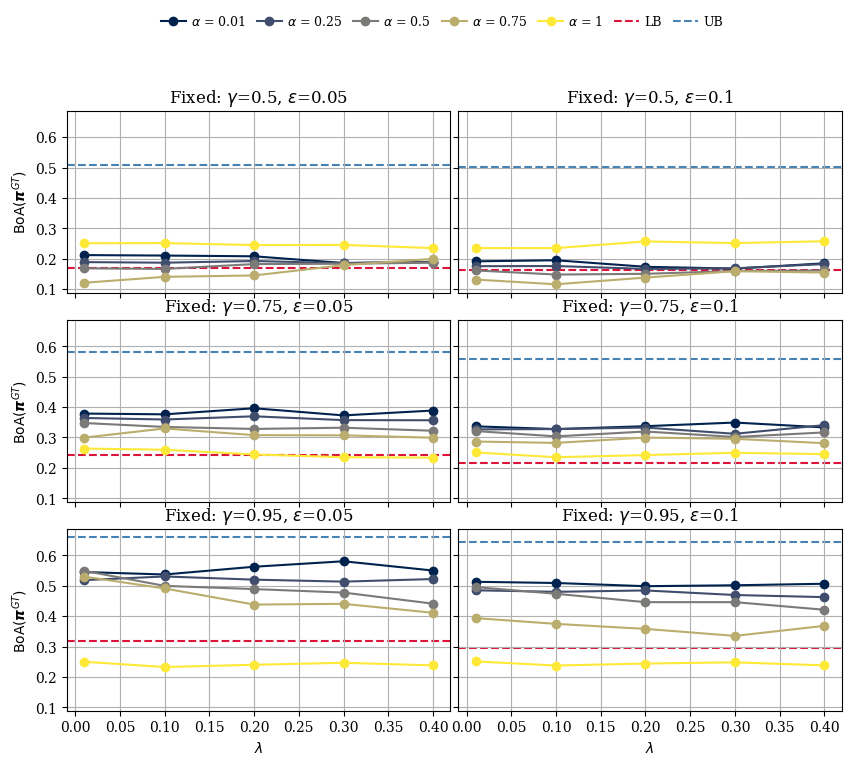

In [21]:
# Overlay aggregate LB/UB on uniform-init simulation panels (total boundaries)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'

# (label, uniform-init simulation dataframe, payoff (t,r,p,s), colormap)
agg_presets = [
    ('0702', df_2000_0702, dict(t=1, r=0.7, p=0.2, s=0), 'viridis'),
    ('0805', df_2000_0805, dict(t=1, r=0.8, p=0.5, s=0), 'cividis'),
]

for label, df_sim, payoff, cmap in agg_presets:
    # Closed-form B_hat, C_hat, D_hat feed the Prop. 17 aggregate bounds:
    #   LB = (1/16)(1 + 2*B_hat + 2*C_hat + 2*D_hat),  UB = (1/16)(8 + 2*B_hat + 2*D_hat)
    theoretical_bounds = [
        get_aggregate_bounds_prop17(epsilon=ps['e'], d=ps['delta'], **payoff)
        for ps in param_sets
    ]
    print(f"Aggregate Prop. 17 bounds - payoff {label} (R={payoff['r']}, P={payoff['p']})")
    for x_var, varying_var in [('alpha', 'lambda'), ('lambda', 'alpha')]:
        plot_multiple_panels(
            df_sim, param_sets, x_var=x_var, varying_var=varying_var, y_var=y, m=2000,
            use_same_scale=True, cmap=cmap, theoretical_bounds=theoretical_bounds,
            theoretical_bounds_labels=(r'LB', r'UB'),
            y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$',
        )


## Validate $\hat{B}$, $\hat{C}$, $\hat{D}$ against saved simulations

| Hat | Profile | CSV | Sim column |
|-----|---------|-----|------------|
| $\hat{B}$ | (AD, GT) | `results_vect_paramsfixed_time2000_ADGT.csv` | `P_GT` |
| $\hat{C}$ | (AC, GT) | `ACGT_Chat_validate_*.csv` | `P_direct_GT_analytic` |
| $\hat{D}$ | (AC, AD) | `results_vect_paramsfixed_time2000_ACAD*.csv` | `P_GT` |

Data: `df_chat_0702` / `df_chat_0805` (`record_boundary=True`). The run still goes to convergence; the code **records** which boundary was crossed first and the analytic init probability.

---

### 1. `P_direct_GT_analytic` vs $\hat{C}$

**Question:** From the starting Q-values only, what does the math say about “A1D before BC”?

- No learning trajectory needed.
- For each run: one number in $[0,1]$.
- Average over runs → compare to $\hat{C}$.

**Analogy:** You look at the starting positions on a map and use geometry to guess who wins the race.

**Expectation:** Should match $\hat{C}$ closely. This is the **cleanest theory test**.

---

### 2. `P_direct_GT` vs $\hat{C}$

**Question:** If we actually run the algorithm, how often does A1D get crossed before BC along the path?

- Binary per run: yes/no.
- Average over runs → compare to $\hat{C}$.

**Analogy:** Same race, but you watch the runners move step by step (finite $\alpha$).

**Expectation:** Should be close to $\hat{C}$ when $\alpha,\lambda$ are small. Can differ a bit because discrete updates aren’t exactly the continuous limit.

**Difference from (1):** (1) = math from start only; (2) = what really happened during learning.

---

### 3. `P_GT` vs band $[\hat{C}, 1]$

**Question:** How often does the run **end** at (GT, GT)?

That includes:
- runs where A1D was first (direct), **and**
- runs where BC was first but you still reached GT later (indirect).

So $P_{\mathrm{GT}} \ge \hat{C}$ always (in theory).

**Analogy:** $\hat{C}$ = “how often you take the direct highway.” `P_GT` = “how often you arrive at the destination,” including people who took a detour.

**Plot:** not a single $\hat{C}$ line — a **band** from $\hat{C}$ up to 1. The sim curve should sit **inside** that band.

A gap **above** $\hat{C}$ is normal: that’s the indirect route working.


In [22]:
# df_chat_0702 / df_chat_0805 loaded above (ACGT_Chat_validate_*.csv, record_boundary=True)
assert "P_direct_GT_analytic" in df_chat_0702.columns, "Re-run the data-loading cell for Chat validate CSVs"
print("Chat validate 0702 rows:", len(df_chat_0702))
print("Chat validate 0805 rows:", len(df_chat_0805))
df_chat_0702.head(3)


Chat validate 0702 rows: 225
Chat validate 0805 rows: 225


,M,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv,time_max,time_min,time_mean,P_direct_GT,P_via_ACAD,P_direct_GT_analytic
0,2000,0.01,0.01,0.05,0.50,False,0.4420,0.5580,0,0.536864,0.129186,0.316529,0.3620,0.6355,0.3595
1,2000,0.01,0.01,0.05,0.75,False,0.1115,0.8885,0,0.587324,0.141472,0.364703,0.3160,0.6830,0.3125
2,2000,0.01,0.01,0.05,0.95,False,0.0125,0.9875,0,0.869187,0.234966,0.572206,0.1805,0.8195,0.1790


In [23]:
from basin import add_hat_column, PAYOFF_PRESETS


def summarize_c_hat_validation(df, label, t, r, p, s):
    df = add_hat_column(df, "C_hat", t=t, r=r, p=p, s=s)
    df["err_analytic"] = df["P_direct_GT_analytic"] - df["C_hat"]
    df["err_direct"] = df["P_direct_GT"] - df["C_hat"]
    print(f"\n=== C_hat vs ACGT Chat {label} (R={r}, P={p}) ===")
    print(f"P_direct_GT_analytic: MAE={df['err_analytic'].abs().mean():.4f}")
    print(f"P_direct_GT trajectory: MAE={df['err_direct'].abs().mean():.4f}")
    display(df[["delta", "e", "alpha", "lambda", "C_hat", "P_direct_GT_analytic", "P_direct_GT", "P_GT"]].round(4))
    return df


def summarize_d_hat_validation(df, label, t, r, p, s, n_mc=50_000):
    df = add_hat_column(df, "D_hat", t=t, r=r, p=p, s=s, n_mc=n_mc)
    print(f"\n=== D_hat vs ACAD {label} (R={r}, P={p}) ===")
    print(f"P_GT vs D_hat: MAE={(df['P_GT'] - df['D_hat']).abs().mean():.4f}")
    display(df[["delta", "e", "alpha", "lambda", "D_hat", "P_GT"]].round(4))
    return df


def summarize_b_hat_validation(df, label, t, r, p, s):
    df = add_hat_column(df, "B_hat", t=t, r=r, p=p, s=s)
    print(f"\n=== B_hat vs ADGT {label} (R={r}, P={p}) ===")
    print(f"P_GT vs B_hat: MAE={(df['P_GT'] - df['B_hat']).abs().mean():.4f}")
    display(df[["delta", "e", "alpha", "lambda", "B_hat", "P_GT"]].round(4))
    return df


df_chat_0702 = summarize_c_hat_validation(df_chat_0702, "0702", **PAYOFF_PRESETS["0702"])
df_chat_0805 = summarize_c_hat_validation(df_chat_0805, "0805", **PAYOFF_PRESETS["0805"])
summarize_d_hat_validation(df_ACAD0702, "0702", **PAYOFF_PRESETS["0702"])
summarize_d_hat_validation(df_ACAD0805, "0805", **PAYOFF_PRESETS["0805"])
summarize_b_hat_validation(df_ADGT0702, "0702", **PAYOFF_PRESETS["0702"])
summarize_b_hat_validation(df_ADGT0805, "0805", **PAYOFF_PRESETS["0805"])



=== C_hat vs ACGT Chat 0702 (R=0.7, P=0.2) ===
P_direct_GT_analytic: MAE=0.0355
P_direct_GT trajectory: MAE=0.1500


,delta,e,alpha,lambda,C_hat,P_direct_GT_analytic,P_direct_GT,P_GT
0,0.50,0.05,0.01,0.01,0.3213,0.3595,0.3620,0.5580
1,0.75,0.05,0.01,0.01,0.2883,0.3125,0.3160,0.8885
2,0.95,0.05,0.01,0.01,0.1459,0.1790,0.1805,0.9875
3,0.50,0.10,0.01,0.01,0.3128,0.3575,0.3620,0.4935
4,0.75,0.10,0.01,0.01,0.2595,0.3200,0.3235,0.8660
...,...,...,...,...,...,...,...,...
220,0.50,0.20,1.00,0.40,0.3046,0.3490,0.3625,0.5070
221,0.75,0.20,1.00,0.40,0.2328,0.2660,0.3400,0.4880
222,0.95,0.05,1.00,0.40,0.1459,0.1810,0.3445,0.4955
223,0.95,0.10,1.00,0.40,0.0976,0.1210,0.3560,0.5005



=== C_hat vs ACGT Chat 0805 (R=0.8, P=0.5) ===
P_direct_GT_analytic: MAE=0.0404
P_direct_GT trajectory: MAE=0.2158


,delta,e,alpha,lambda,C_hat,P_direct_GT_analytic,P_direct_GT,P_GT
0,0.50,0.05,0.01,0.01,0.7864,0.7750,0.7760,0.8115
1,0.75,0.05,0.01,0.01,0.7811,0.7380,0.7370,0.9215
2,0.95,0.05,0.01,0.01,0.7548,0.7170,0.7185,0.9815
3,0.50,0.10,0.01,0.01,0.7726,0.7375,0.7385,0.7625
4,0.75,0.10,0.01,0.01,0.7631,0.7230,0.7220,0.8945
...,...,...,...,...,...,...,...,...
220,0.50,0.20,1.00,0.40,0.7444,0.6950,0.3500,0.0000
221,0.75,0.20,1.00,0.40,0.7294,0.6700,0.3520,0.5065
222,0.95,0.05,1.00,0.40,0.7548,0.7100,0.3375,0.4915
223,0.95,0.10,1.00,0.40,0.7289,0.6935,0.3590,0.4985



=== D_hat vs ACAD 0702 (R=0.7, P=0.2) ===
P_GT vs D_hat: MAE=0.0759


,delta,e,alpha,lambda,D_hat,P_GT
0,0.50,0.05,0.01,0.01,0.0385,0.0555
1,0.75,0.05,0.01,0.01,0.2993,0.3230
2,0.95,0.05,0.01,0.01,0.4450,0.4625
3,0.50,0.10,0.01,0.01,0.0183,0.0295
4,0.75,0.10,0.01,0.01,0.2569,0.2940
...,...,...,...,...,...,...
220,0.50,0.20,1.00,0.40,0.0003,0.0000
221,0.75,0.20,1.00,0.40,0.1579,0.0000
222,0.95,0.05,1.00,0.40,0.4450,0.0000
223,0.95,0.10,1.00,0.40,0.4117,0.0000


... (3 outputs left out)

,delta,e,alpha,lambda,B_hat,P_GT
225,0.75,0.05,0.01,0.01,0.8888,0.8570
226,0.50,0.05,0.01,0.01,0.3545,0.3770
227,0.95,0.05,0.01,0.01,0.9760,0.9715
228,0.50,0.10,0.01,0.01,0.2284,0.2600
229,0.75,0.10,0.01,0.01,0.8518,0.8400
...,...,...,...,...,...,...
445,0.50,0.20,1.00,0.40,0.0238,0.5195
446,0.75,0.20,1.00,0.40,0.7273,0.5020
447,0.95,0.20,1.00,0.01,0.9075,0.4985
448,0.95,0.10,1.00,0.40,0.9591,0.5165



=== B_hat vs ADGT 0805 (R=0.8, P=0.5) ===
P_GT vs B_hat: MAE=0.0834


,delta,e,alpha,lambda,B_hat,P_GT
0,0.50,0.05,0.01,0.01,0.0580,0.0805
1,0.75,0.05,0.01,0.01,0.5241,0.5195
2,0.95,0.05,0.01,0.01,0.9015,0.8840
3,0.50,0.10,0.01,0.01,0.0187,0.0190
4,0.75,0.10,0.01,0.01,0.3886,0.4245
...,...,...,...,...,...,...
220,0.50,0.20,1.00,0.40,0.0532,0.0000
221,0.75,0.20,1.00,0.40,0.1862,0.5090
222,0.95,0.10,1.00,0.40,0.8345,0.5085
223,0.95,0.05,1.00,0.40,0.9015,0.4925


,M,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv,time_max,time_min,time_mean,B_hat
0,2000,0.01,0.01,0.05,0.50,False,0.9195,0.0805,0,0.153801,0.109268,0.134918,0.058013
1,2000,0.01,0.01,0.05,0.75,False,0.4805,0.5195,0,0.185144,0.126314,0.147893,0.524055
2,2000,0.01,0.01,0.05,0.95,False,0.1160,0.8840,0,0.267120,0.209121,0.236676,0.901500
3,2000,0.01,0.01,0.10,0.50,False,0.9810,0.0190,0,0.159754,0.109925,0.136639,0.018744
4,2000,0.01,0.01,0.10,0.75,False,0.5755,0.4245,0,0.182518,0.126224,0.149686,0.388580
...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,2000,1.00,0.40,0.20,0.50,False,1.0000,0.0000,0,0.006812,0.002916,0.003755,0.053191
221,2000,1.00,0.40,0.20,0.75,False,0.4910,0.5090,0,0.041264,0.005761,0.010040,0.186170
222,2000,1.00,0.40,0.10,0.95,False,0.4915,0.5085,0,0.178160,0.029201,0.050484,0.834529
223,2000,1.00,0.40,0.05,0.95,False,0.5075,0.4925,0,0.254267,0.027704,0.065288,0.901500


<>:45: SyntaxWarning: invalid escape sequence '\h'
<>:45: SyntaxWarning: invalid escape sequence '\h'
/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_48822/2122171839.py:45: SyntaxWarning: invalid escape sequence '\h'
  """


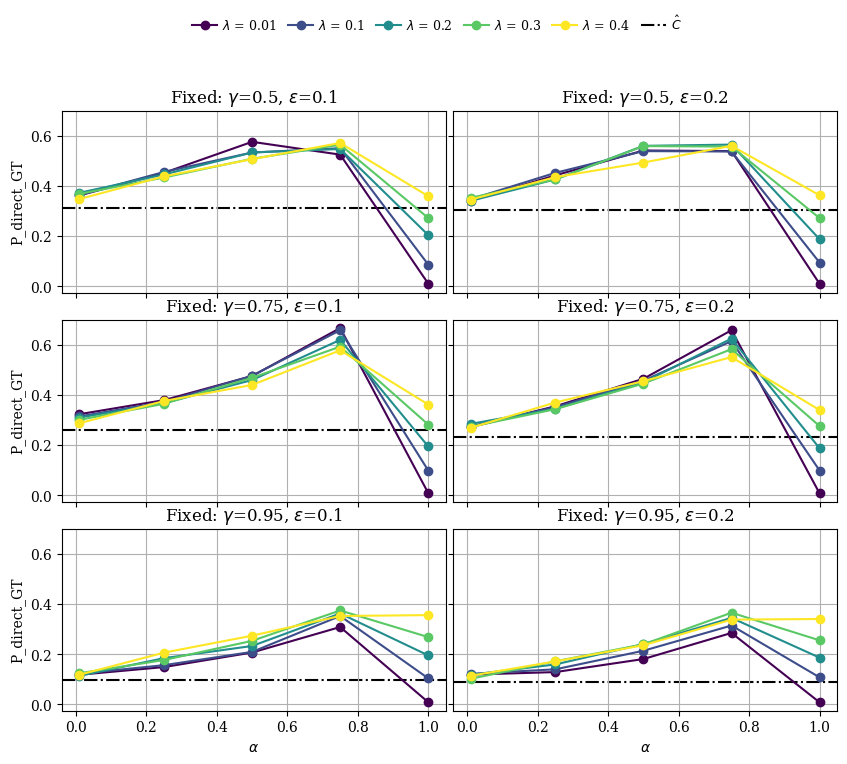

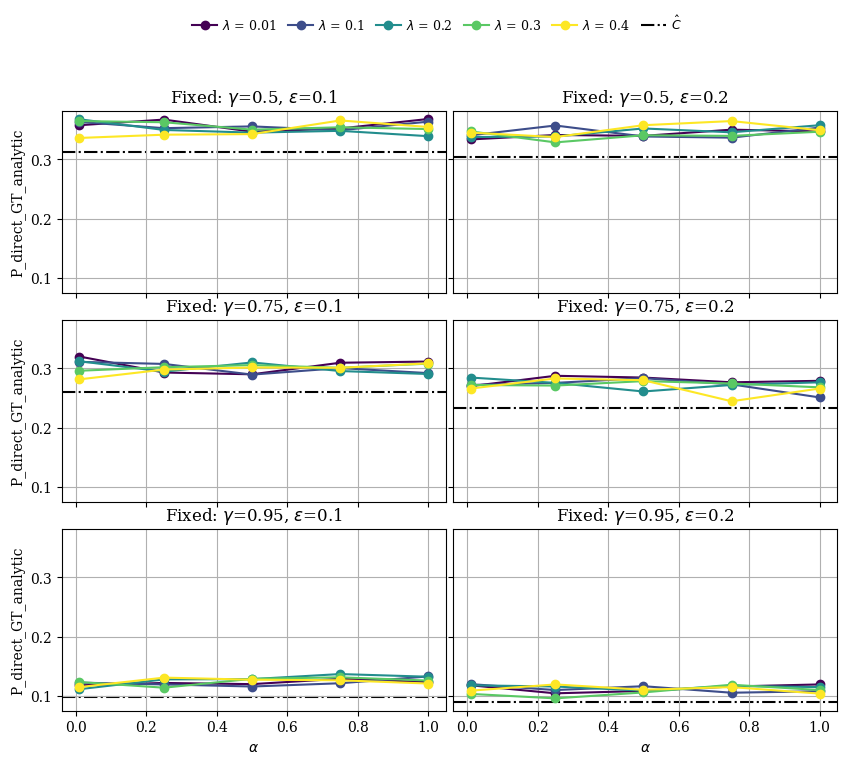

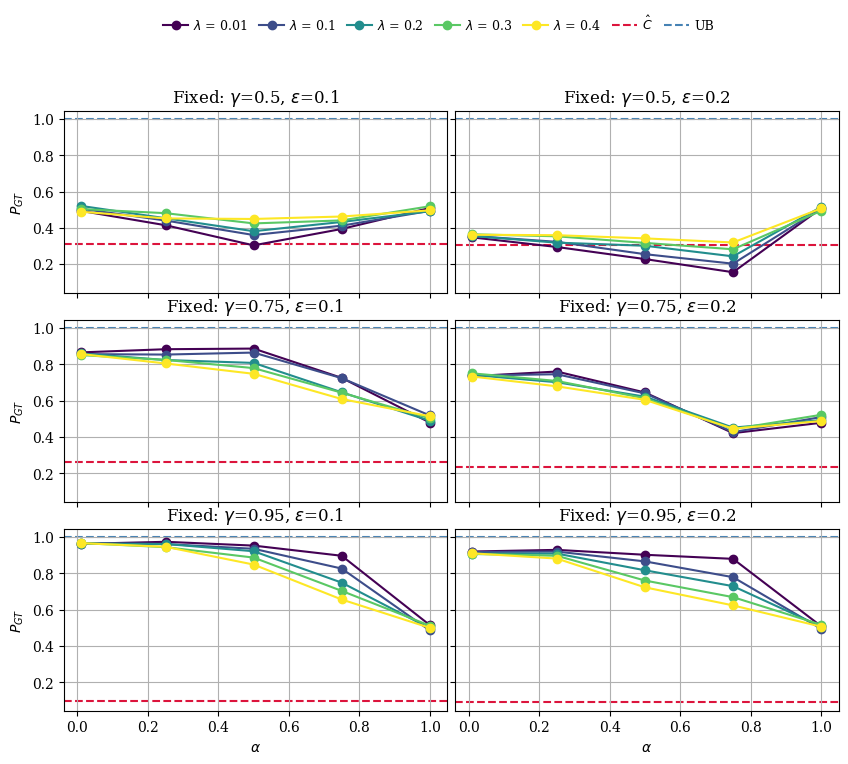

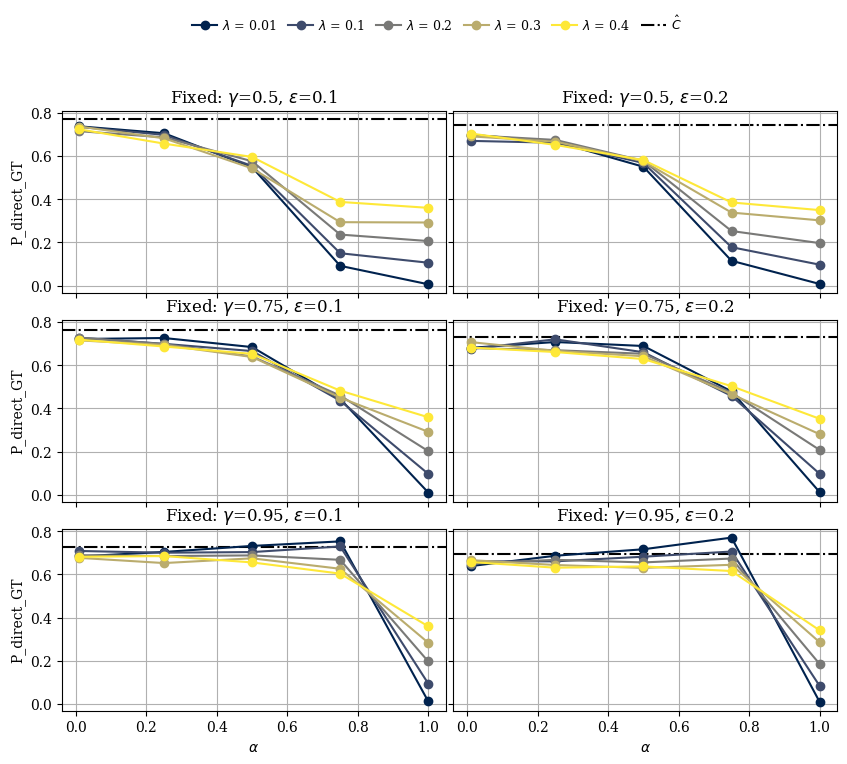

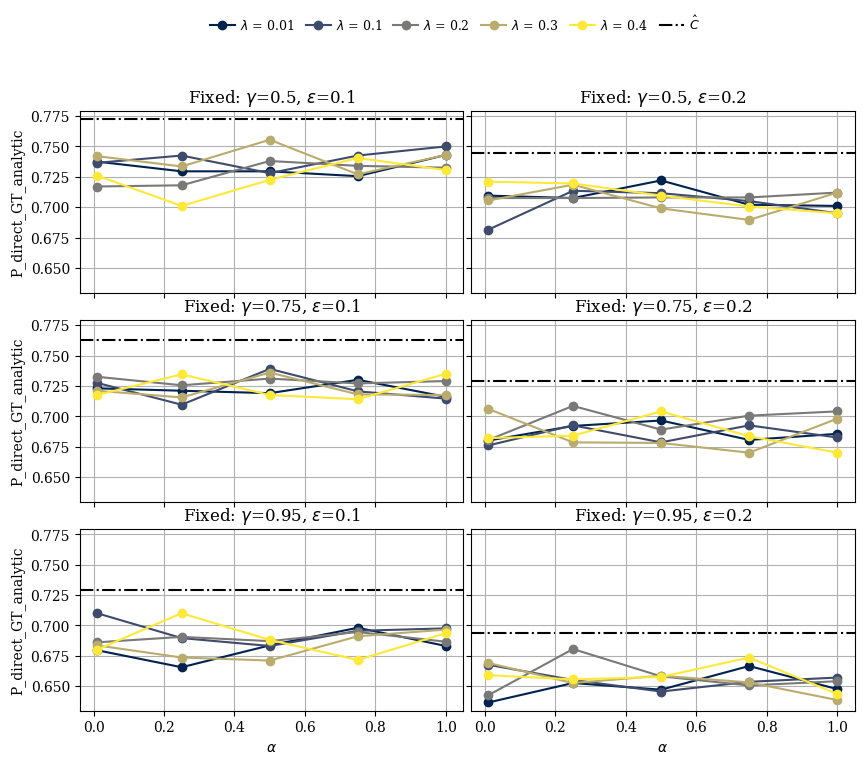

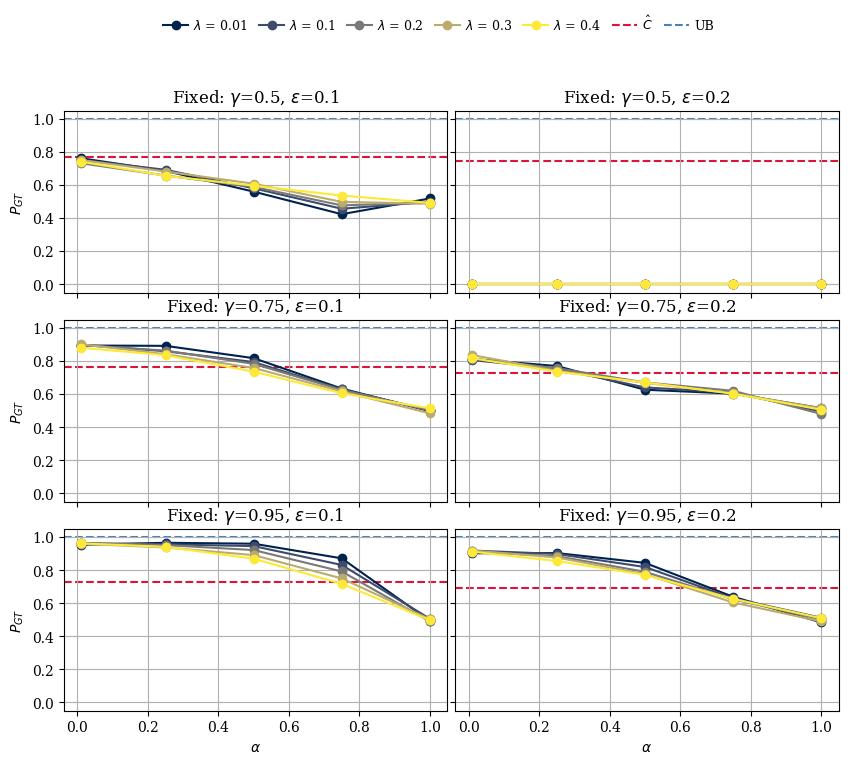

In [24]:
_ALL_PANELS_CHAT = [
    {"delta": 0.5, "e": 0.1},
    {"delta": 0.5, "e": 0.2},
    {"delta": 0.75, "e": 0.1},
    {"delta": 0.75, "e": 0.2},
    {"delta": 0.95, "e": 0.1},
    {"delta": 0.95, "e": 0.2},
]
_MAX_PANELS = 6  # plot_multiple_panels uses a 3x2 grid


def _panels_in_df(df):
    return [
        ps for ps in _ALL_PANELS_CHAT
        if not df[(df["delta"] == ps["delta"]) & (df["e"] == ps["e"])].empty
    ]


def _chunk(lst, size):
    for i in range(0, len(lst), size):
        yield lst[i:i + size]


def plot_chat_validation(df, t, r, p, s, cmap, title_prefix):
    param_sets = _panels_in_df(df)
    m_chat = int(df["M"].iloc[0])

    for chunk_i, ps_chunk in enumerate(_chunk(param_sets, _MAX_PANELS)):
        chat_hat = [
            theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps["delta"], epsilon=ps["e"])
            for ps in ps_chunk
        ]
        tag = f" {title_prefix}" if len(param_sets) <= _MAX_PANELS else f" {title_prefix} [{chunk_i + 1}]"

        for y_var, ylabel in [
            ("P_direct_GT", r"$P(\mathrm{A1D\ first})$"),
            ("P_direct_GT_analytic", r"$P(T_{A1D}<T_{BC})$ at init"),
        ]:
            plot_multiple_panels(
                df, ps_chunk, x_var="alpha", varying_var="lambda", y_var=y_var,
                m=m_chat, use_same_scale=True, cmap=cmap,
                theoretical_basin_AD=chat_hat, theoretical_line_label=r"$\hat{C}$",
                y_axis_label=rf"{tag}: {ylabel}",
            )
            """
            plot_multiple_panels(
                df, ps_chunk, x_var="lambda", varying_var="alpha", y_var=y_var,
                m=m_chat, use_same_scale=True, cmap=cmap,
                theoretical_basin_AD=chat_hat, theoretical_line_label=r"$\hat{C}$",
                y_axis_label=rf"{tag}: {ylabel}",
            )
            """

        chat_bounds = [(c, 1.0) for c in chat_hat]
        plot_multiple_panels(
            df, ps_chunk, x_var="alpha", varying_var="lambda", y_var="P_GT",
            m=m_chat, use_same_scale=True, cmap=cmap,
            theoretical_bounds=chat_bounds,
            theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
            y_axis_label=rf"{tag}: $\\mathrm{{BoA}}(\\boldsymbol{{\\pi}}^{{GT}}\\mid(AC,GT))$",
        )


plot_chat_validation(df_chat_0702, t=1, r=0.7, p=0.2, s=0, cmap="viridis", title_prefix="0702")
plot_chat_validation(df_chat_0805, t=1, r=0.8, p=0.5, s=0, cmap="cividis", title_prefix="0805")


### Export appendix figures (`paper.tex` → `images/`)

Run after loading `df_ACGT*`, `df_ACAD*`, and `df_chat_*`. Writes filenames used in Appendix~\ref{app:acgt}.

In [25]:
# Export appendix figures for paper.tex (Appendix~\ref{app:acgt})
import os

if os.path.basename(os.getcwd()) == "MultiAgent":
    _PAPER_IMAGES = os.path.abspath(os.path.join(os.getcwd(), "..", "images"))
else:
    _PAPER_IMAGES = os.path.abspath(os.path.join(os.getcwd(), "images"))

os.makedirs(_PAPER_IMAGES, exist_ok=True)

_PAPER_PARAM_SETS = [
    {"delta": 0.5, "e": 0.05},
    {"delta": 0.5, "e": 0.2},
    {"delta": 0.75, "e": 0.05},
    {"delta": 0.75, "e": 0.2},
    {"delta": 0.95, "e": 0.05},
    {"delta": 0.95, "e": 0.2},
]

_PLOT_KW = dict(
    param_sets=_PAPER_PARAM_SETS,
    x_var="alpha",
    varying_var="lambda",
    m=2000,
    use_same_scale=True,
    show=False,
)


def _save_acgt_boa(df, t, r, p, s, cmap, filename):
    chat_hat = [
        theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps["delta"], epsilon=ps["e"])
        for ps in _PAPER_PARAM_SETS
    ]
    bounds = [(c, 1.0) for c in chat_hat]
    path = os.path.join(_PAPER_IMAGES, filename)
    plot_multiple_panels(
        df,
        y_var="P_GT",
        cmap=cmap,
        theoretical_bounds=bounds,
        theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
        y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$",
        save_path=path,
        **_PLOT_KW,
    )
    print("saved", path)


def _save_acgt_boundary(df, t, r, p, s, cmap, filename):
    chat_hat = [
        theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps["delta"], epsilon=ps["e"])
        for ps in _PAPER_PARAM_SETS
    ]
    path = os.path.join(_PAPER_IMAGES, filename)
    plot_multiple_panels(
        df,
        y_var="P_direct_GT_analytic",
        cmap=cmap,
        theoretical_basin_AD=chat_hat,
        theoretical_line_label=r"$\hat{C}$",
        y_axis_label=r"$P(T_{A1D}<T_{BC})$ at init",
        save_path=path,
        **_PLOT_KW,
    )
    print("saved", path)


def _save_acad_boa(df, t, r, p, s, cmap, filename):
    d_hat = [
        theoretical_D_hat_from_ACAD(t=t, r=r, p=p, s=s, delta=ps["delta"], e=ps["e"])
        for ps in _PAPER_PARAM_SETS
    ]
    path = os.path.join(_PAPER_IMAGES, filename)
    plot_multiple_panels(
        df,
        y_var="P_GT",
        cmap=cmap,
        theoretical_basin_AD=d_hat,
        theoretical_line_label=r"$\hat{D}$",
        y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,AD))$",
        save_path=path,
        **_PLOT_KW,
    )
    print("saved", path)


# (AC,GT) full BoA vs C_hat
_save_acgt_boa(df_ACGT0702, t=1, r=0.7, p=0.2, s=0, cmap="viridis", filename="af0702_acgt.png")
_save_acgt_boa(df_ACGT0805, t=1, r=0.8, p=0.5, s=0, cmap="cividis", filename="af_0805_acgt.png")

# (AC,GT) first-crossing validation of C_hat
_save_acgt_boundary(df_chat_0702, t=1, r=0.7, p=0.2, s=0, cmap="viridis", filename="af0702_acgt_boundary.png")
_save_acgt_boundary(df_chat_0805, t=1, r=0.8, p=0.5, s=0, cmap="cividis", filename="af0805_acgt_boundary.png")

# (AC,AD) BoA vs D_hat
_save_acad_boa(df_ACAD0702, t=1, r=0.7, p=0.2, s=0, cmap="viridis", filename="af0702_acad.png")
_save_acad_boa(df_ACAD0805, t=1, r=0.8, p=0.5, s=0, cmap="cividis", filename="af0805_acad.png")

# Entry plane for (AC,AD) -> (GT,AD)  (Figure~\ref{fig:acad-entry})
_xh, _yh = sample_acad_entry_points(t=1, r=0.7, p=0.2, s=0, epsilon=0.01, d=0.6, n=300, seed=7)
_fig_entry, _ax_entry = plot_acad_entry_validation(
    t=1, r=0.7, p=0.2, s=0, epsilon=0.01, d=0.6,
    entry_points=(_xh, _yh),
    title=r"$(AC,AD)\to(GT,AD)$ entry plane",
)
_entry_path = os.path.join(_PAPER_IMAGES, "acad_entry_plane.png")
_fig_entry.savefig(_entry_path, dpi=300, bbox_inches="tight")
plt.close(_fig_entry)
print("saved", _entry_path)

saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/af0702_acgt.png
saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/af_0805_acgt.png
saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/af0702_acgt_boundary.png
saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/af0805_acgt_boundary.png
saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/af0702_acad.png
saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/af0805_acad.png
saved /Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/images/acad_entry_plane.png
